# Project 2
## Goals
Use scheduled flight information to predict:

1. Binary classification:
- 0: flight delays under 15 minutes
- 1: flight delays of 15 minutes or more

2. Multiclass classification:
- 0: flight delays under 15 minutes
- 1: flight delays of 15 minutes or more and under 60 minutes
- 2: flight delays of 60 minutes or more

In [2]:
%pip install numpy pandas matplotlib scikit-learn seaborn jupyter

Defaulting to user installation because normal site-packages is not writeable
You should consider upgrading via the '/Library/Developer/CommandLineTools/usr/bin/python3 -m pip install --upgrade pip' command.
Note: you may need to restart the kernel to use updated packages.


In [3]:
from pathlib import Path
from time import perf_counter
import json
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

In [4]:
SEED = 10
MAX_SAMPLES = 20000
CV_FOLDS = 5
OUTPUT_DIR = Path("project2_output")
OUTPUT_DIR.mkdir(exist_ok=True)

In [5]:
from pathlib import Path

print("Current working directory:")
print(Path.cwd())

print("\nFiles in current directory:")
print(list(Path.cwd().iterdir()))

Current working directory:
/Users/emilyiorio/Desktop/School/DataMining/cse5104-project2

Files in current directory:
[PosixPath('/Users/emilyiorio/Desktop/School/DataMining/cse5104-project2/.DS_Store'), PosixPath('/Users/emilyiorio/Desktop/School/DataMining/cse5104-project2/model_fitting.ipynb'), PosixPath('/Users/emilyiorio/Desktop/School/DataMining/cse5104-project2/README.md'), PosixPath('/Users/emilyiorio/Desktop/School/DataMining/cse5104-project2/.gitignore'), PosixPath('/Users/emilyiorio/Desktop/School/DataMining/cse5104-project2/preprocessing.py'), PosixPath('/Users/emilyiorio/Desktop/School/DataMining/cse5104-project2/project2_output'), PosixPath('/Users/emilyiorio/Desktop/School/DataMining/cse5104-project2/req.txt'), PosixPath('/Users/emilyiorio/Desktop/School/DataMining/cse5104-project2/.ipynb_checkpoints'), PosixPath('/Users/emilyiorio/Desktop/School/DataMining/cse5104-project2/.git'), PosixPath('/Users/emilyiorio/Desktop/School/DataMining/cse5104-project2/data')]


In [6]:
for file in Path.cwd().rglob("*.csv"):
    print(file)

/Users/emilyiorio/Desktop/School/DataMining/cse5104-project2/project2_output/cv_results_binary_ann.csv
/Users/emilyiorio/Desktop/School/DataMining/cse5104-project2/project2_output/cv_results_binary_random_forest.csv
/Users/emilyiorio/Desktop/School/DataMining/cse5104-project2/project2_output/cv_results_reduced_binary_random_forest.csv
/Users/emilyiorio/Desktop/School/DataMining/cse5104-project2/project2_output/flights_reduced_multiclass_validation.csv
/Users/emilyiorio/Desktop/School/DataMining/cse5104-project2/project2_output/cv_results_reduced_multiclass_random_forest.csv
/Users/emilyiorio/Desktop/School/DataMining/cse5104-project2/project2_output/cv_results_multiclass_knn.csv
/Users/emilyiorio/Desktop/School/DataMining/cse5104-project2/project2_output/model_fitting_results_reduced.csv
/Users/emilyiorio/Desktop/School/DataMining/cse5104-project2/project2_output/cv_results_reduced_binary_naive_bayes.csv
/Users/emilyiorio/Desktop/School/DataMining/cse5104-project2/project2_output/cv_re

In [7]:
categorical_features = [
    "AIRLINE",
    "ORIGIN_AIRPORT",
    "DESTINATION_AIRPORT",
]

numeric_features = [
    "MONTH",
    "DAY",
    "DAY_OF_WEEK",
    "SCHEDULED_DEPARTURE_HOUR",
    "SCHEDULED_DEPARTURE_MINUTE",
    "SCHEDULED_ARRIVAL_HOUR",
    "SCHEDULED_ARRIVAL_MINUTE",
    "SCHEDULED_TIME",
    "DISTANCE",
]

source_columns = [
    "MONTH",
    "DAY",
    "DAY_OF_WEEK",
    "AIRLINE",
    "ORIGIN_AIRPORT",
    "DESTINATION_AIRPORT",
    "SCHEDULED_DEPARTURE",
    "SCHEDULED_ARRIVAL",
    "SCHEDULED_TIME",
    "DISTANCE",
    "ARRIVAL_DELAY",
    "CANCELLED",
    "DIVERTED",
]

def process_HHMM_time(data):
    values = pd.to_numeric(data, errors="coerce")
    valid = values.notna() & values.mod(1).eq(0) & ((values.between(0, 2359) & values.mod(100).lt(60)) | values.eq(2400))
    values = values.where(valid).replace(2400, 0)
    return values.floordiv(100), values.mod(100)

processed_path = Path("data/preprocessed_flights.csv")
raw_path = Path("data/flights.csv")

data_path = processed_path if processed_path.exists() else raw_path

if not data_path.exists():
    raise FileNotFoundError(
        "File not found."
    )

df = pd.read_csv(
    data_path,
    usecols=lambda column: column in source_columns,
    dtype={column: "string" for column in categorical_features},
    low_memory=False,
)

loaded_rows = len(df)

for column in set(df.columns) - set(categorical_features):
    df[column] = pd.to_numeric(df[column], errors="coerce")

if "CANCELLED" in df.columns:
    df = df.loc[df["CANCELLED"].eq(0)].copy()

df = df.loc[
    df["DIVERTED"].eq(0)
    & df["ARRIVAL_DELAY"].notna()
    & np.isfinite(df["ARRIVAL_DELAY"])
].copy()

eligible_rows = len(df)

if MAX_SAMPLES is not None and len(df) > MAX_SAMPLES:
    df = df.sample(n=MAX_SAMPLES, random_state=SEED)

df = df.reset_index(drop=True)

# Normalize categorical missing values
for column in categorical_features:
    values = df[column].astype("string").str.strip()
    df[column] = values.replace("", pd.NA).astype(object)
    df.loc[pd.isna(df[column]), column] = np.nan

if len(df) < 200:
    raise ValueError("The project requires at least 200 samples per problem.")

df["SCHEDULED_DEPARTURE_HOUR"], df["SCHEDULED_DEPARTURE_MINUTE"] = process_HHMM_time(df["SCHEDULED_DEPARTURE"])
df["SCHEDULED_ARRIVAL_HOUR"], df["SCHEDULED_ARRIVAL_MINUTE"] = process_HHMM_time(df["SCHEDULED_ARRIVAL"])

print("Source:", data_path)
print(f"Loaded rows: {loaded_rows:,}")
print(f"Eligible rows: {eligible_rows:,}")
print(f"Selected rows: {len(df):,}")

display(df.head())

Source: data/flights.csv
Loaded rows: 5,819,079
Eligible rows: 5,714,008
Selected rows: 20,000


,MONTH,DAY,DAY_OF_WEEK,AIRLINE,ORIGIN_AIRPORT,DESTINATION_AIRPORT,SCHEDULED_DEPARTURE,SCHEDULED_TIME,DISTANCE,SCHEDULED_ARRIVAL,ARRIVAL_DELAY,DIVERTED,CANCELLED,SCHEDULED_DEPARTURE_HOUR,SCHEDULED_DEPARTURE_MINUTE,SCHEDULED_ARRIVAL_HOUR,SCHEDULED_ARRIVAL_MINUTE
0,12,28,1,WN,DEN,JAX,1825,185.0,1447,2330,58.0,0,0,18,25,23,30
1,3,19,4,MQ,IND,JFK,1245,124.0,665,1449,5.0,0,0,12,45,14,49
2,10,31,6,EV,10397,10685,2109,104.0,533,2153,-8.0,0,0,21,9,21,53
3,8,4,2,UA,SNA,DEN,1542,138.0,846,1900,-10.0,0,0,15,42,19,0
4,3,29,7,UA,DEN,SAN,2207,143.0,853,2330,-12.0,0,0,22,7,23,30


# Predictors:
- Date of flight (Month, day, and day of week)
- scheduled duration
- scheduled distance
- scheduled departure hour and minute
- scheduled arrival hour and minute
- airline
- origin airport
- destination airport

# Excluded predictors:
- Actual departure time
- Actual arrival time
- Departure delay
- Taxi times
- elapsed time
- delay-cause
These variables are removed from the data frame to prevent outcome leakage.

# response variable: 
- Arrival delay

In [8]:
feature_cols = categorical_features + numeric_features
X = df[feature_cols].copy()

X[numeric_features] = X[numeric_features].replace([np.inf, -np.inf], np.nan).astype(float)

targets = {
    "binary": df["ARRIVAL_DELAY"].ge(15).astype(int),
    "multiclass": pd.Series(np.select([
        df["ARRIVAL_DELAY"].lt(15),
        df["ARRIVAL_DELAY"].lt(60),
    ], [0, 1], default=2),
    index=df.index),
}

class_names = {
    "binary": ["on_time", "delayed"],
    "multiclass": ["on_time", "minor_delay", "major_delay"],
}

for classificationtype in targets:
    targets[classificationtype] = targets[classificationtype].rename(f"{classificationtype}_response")

display(X.isna().mean().to_frame("missing_fraction").sort_values("missing_fraction", ascending=False))

,missing_fraction
AIRLINE,0.0
ORIGIN_AIRPORT,0.0
DESTINATION_AIRPORT,0.0
MONTH,0.0
DAY,0.0
DAY_OF_WEEK,0.0
SCHEDULED_DEPARTURE_HOUR,0.0
SCHEDULED_DEPARTURE_MINUTE,0.0
SCHEDULED_ARRIVAL_HOUR,0.0
SCHEDULED_ARRIVAL_MINUTE,0.0


We will use a stratified 90/10 training/testing split on all of our models.

In [9]:

from sklearn.model_selection import train_test_split

splits = {}

for classificationtype, y in targets.items():
    if y.value_counts().min() < 10:
        raise ValueError(f"Not enough samples for {classificationtype} classification.")

    training, validation = train_test_split(
        np.arange(len(X)),
        test_size=0.10,
        stratify=y,
        random_state=SEED,
    )

    X_train = X.iloc[training].copy()
    y_train = y.iloc[training].copy()
    X_validation = X.iloc[validation].copy()
    y_validation = y.iloc[validation].copy()

    if y_train.value_counts().min() < CV_FOLDS:
        raise ValueError(f"Not enough training samples for {classificationtype} classification.")

    splits[classificationtype] = (X_train, y_train, X_validation, y_validation)

    # all data for task
    pd.concat([X, y], axis=1).to_csv(
        OUTPUT_DIR / f"flights_{classificationtype}.csv",
        index=False,
    )

    # training and validation data for task
    pd.concat([X_train, y_train], axis=1).to_csv(
        OUTPUT_DIR / f"flights_{classificationtype}_train.csv",
        index=False,
    )

    pd.concat([X_validation, y_validation], axis=1).to_csv(
        OUTPUT_DIR / f"flights_{classificationtype}_validation.csv",
        index=False,
    )

    print(f"{classificationtype}: {len(X_train):,} training samples, {len(X_validation):,} validation samples")


binary: 18,000 training samples, 2,000 validation samples
multiclass: 18,000 training samples, 2,000 validation samples


In [10]:
# explore data (visualization and stuff like that)

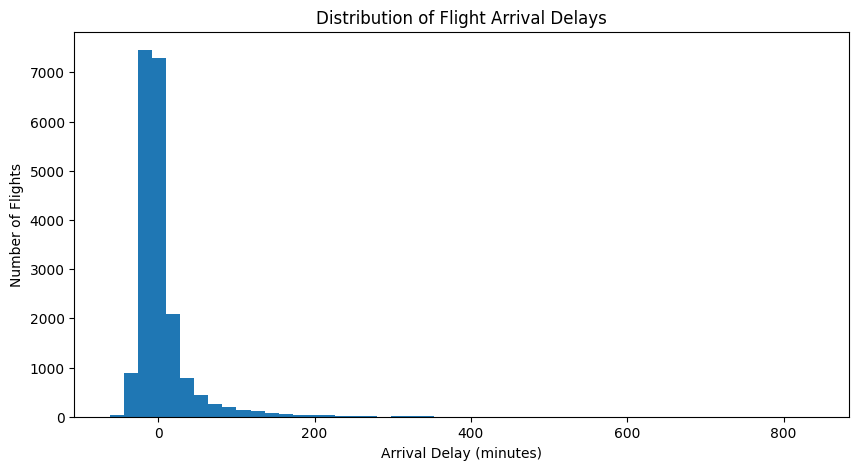

In [11]:
# distribution of arrival delays
plt.figure(figsize=(10, 5))

plt.hist(df["ARRIVAL_DELAY"], bins=50)

plt.xlabel("Arrival Delay (minutes)")
plt.ylabel("Number of Flights")
plt.title("Distribution of Flight Arrival Delays")

plt.show()

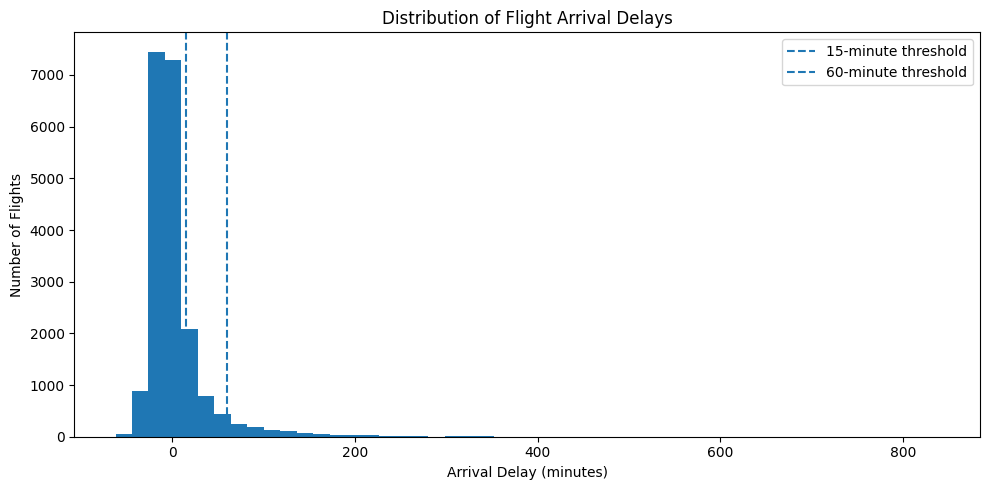

In [12]:
# distribution of arrival delays with classification thresholds
plt.figure(figsize=(10, 5))

plt.hist(df["ARRIVAL_DELAY"], bins=50)

plt.axvline(15, linestyle="--", label="15-minute threshold")
plt.axvline(60, linestyle="--", label="60-minute threshold")

plt.title("Distribution of Flight Arrival Delays")
plt.xlabel("Arrival Delay (minutes)")
plt.ylabel("Number of Flights")
plt.legend()
plt.tight_layout()
plt.show()

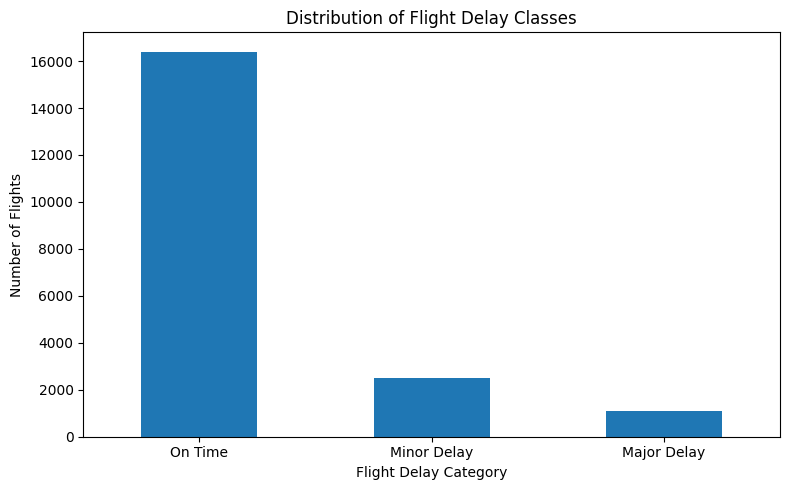

In [13]:
# target class distribution
plt.figure(figsize=(8, 5))

targets["multiclass"].value_counts().sort_index().plot(
    kind="bar"
)

plt.xticks(
    [0, 1, 2],
    ["On Time", "Minor Delay", "Major Delay"],
    rotation=0
)

plt.title("Distribution of Flight Delay Classes")
plt.xlabel("Flight Delay Category")
plt.ylabel("Number of Flights")
plt.tight_layout()
plt.show()

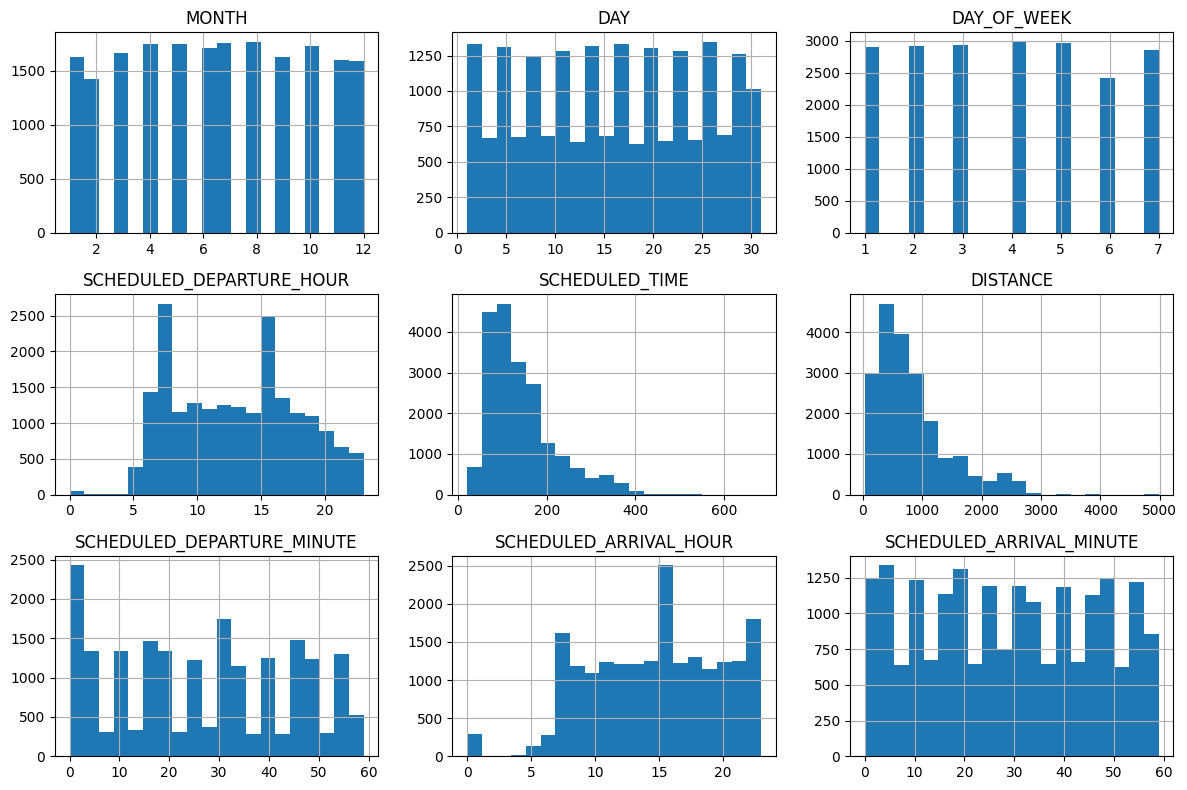

In [14]:
# distribution of numerical features
p_numeric_features = [
    "MONTH",
    "DAY",
    "DAY_OF_WEEK",
    "SCHEDULED_DEPARTURE_HOUR",
    "SCHEDULED_TIME",
    "DISTANCE",
    "SCHEDULED_DEPARTURE_MINUTE",
    "SCHEDULED_ARRIVAL_HOUR",
    "SCHEDULED_ARRIVAL_MINUTE"
]

df[p_numeric_features].hist(
    figsize=(12, 8),
    bins=20
)

plt.tight_layout()
plt.show()

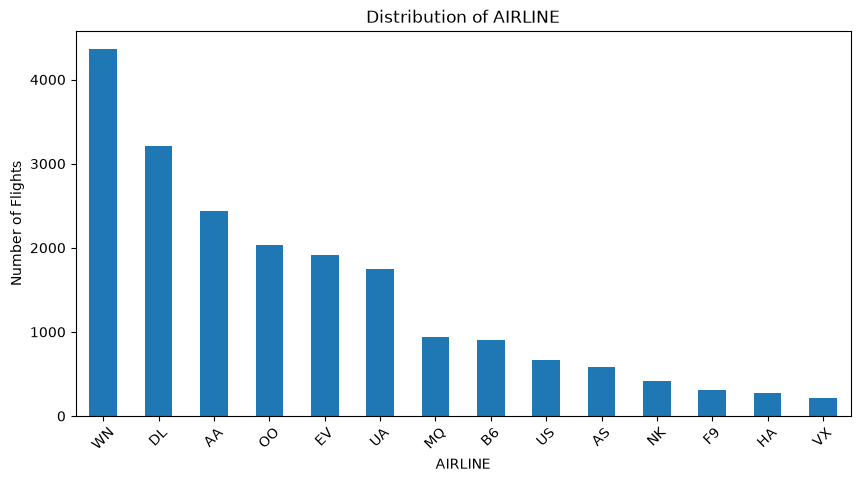

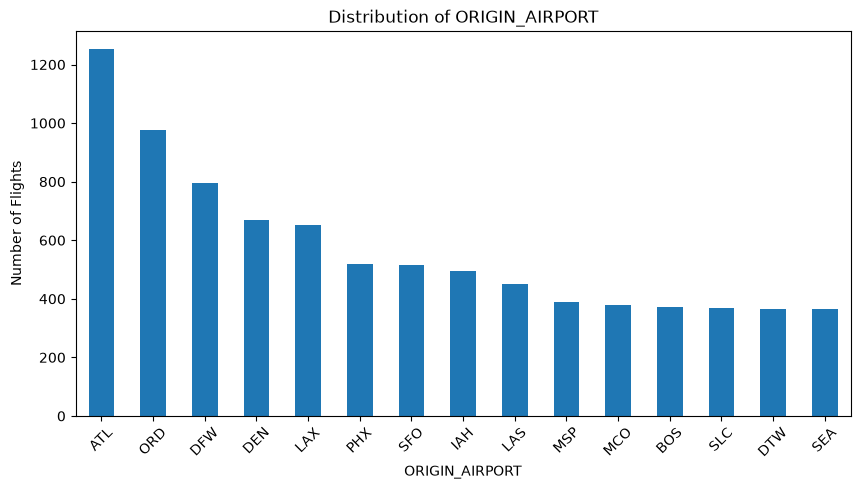

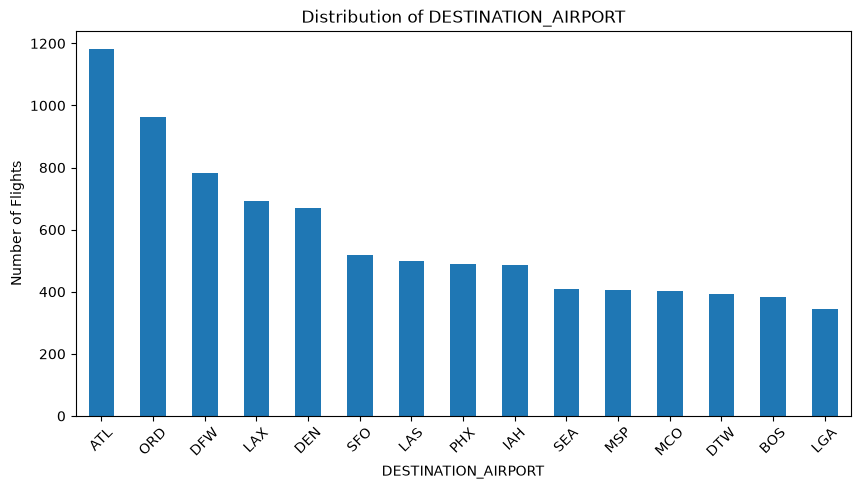

In [14]:
# distribution of categorical predictors
for column in categorical_features:
    plt.figure(figsize=(10, 5))

    df[column].value_counts().head(15).plot(
        kind="bar"
    )

    plt.title(f"Distribution of {column}")
    plt.ylabel("Number of Flights")
    plt.xticks(rotation=45)

    plt.show()

In [15]:
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier

model_specs = {
    "decision_tree": (
        DecisionTreeClassifier(random_state=SEED),
        {"model__max_depth": [3, 5, 10, 15, 20]}
    ),
    "svm": (
        SVC(random_state=SEED),
        {"model__kernel": ["linear", "poly", "rbf"]}
    ),
    "knn": (
        KNeighborsClassifier(n_jobs=-1),
        {
            "model__n_neighbors": [3, 5, 7, 9, 11],
            "model__weights": ["uniform", "distance"]
        }
    ),
    "random_forest": (
        RandomForestClassifier(random_state=SEED, n_jobs=-1),
        {
            "model__max_depth": [5, 10, 15, 20, 25],
            "model__class_weight": [None, "balanced"]
        }
    ),

    "naive_bayes": (
        GaussianNB(),
        {
            "model__var_smoothing": [1e-12, 1e-10, 1e-9, 1e-8, 1e-6]
        }
    ),

    "ann": (
        MLPClassifier(hidden_layer_sizes=(64,), max_iter=300, early_stopping=True, random_state=SEED),
        {
            "model__alpha": [0.00001, 0.0001, 0.001, 0.01, 0.1]
        }
    )
}

models = list(model_specs)
for model in models:
    model_estimator, hyperparameters = model_specs[model]
    print(f"{model}: {model_estimator} with hyperparameters {hyperparameters}")

decision_tree: DecisionTreeClassifier(random_state=10) with hyperparameters {'model__max_depth': [3, 5, 10, 15, 20]}
svm: SVC(random_state=10) with hyperparameters {'model__kernel': ['linear', 'poly', 'rbf']}
knn: KNeighborsClassifier(n_jobs=-1) with hyperparameters {'model__n_neighbors': [3, 5, 7, 9, 11], 'model__weights': ['uniform', 'distance']}
random_forest: RandomForestClassifier(n_jobs=-1, random_state=10) with hyperparameters {'model__max_depth': [5, 10, 15, 20, 25], 'model__class_weight': [None, 'balanced']}
naive_bayes: GaussianNB() with hyperparameters {'model__var_smoothing': [1e-12, 1e-10, 1e-09, 1e-08, 1e-06]}
ann: MLPClassifier(early_stopping=True, hidden_layer_sizes=(64,), max_iter=300,
              random_state=10) with hyperparameters {'model__alpha': [1e-05, 0.0001, 0.001, 0.01, 0.1]}


In [16]:
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.preprocessing import FunctionTransformer
from sklearn.pipeline import Pipeline
from scipy import sparse
from sklearn.feature_selection import SelectPercentile, f_classif

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay,
)

def make_pipeline(model_estimator, selected_features=False):
   
    numeric_transformer = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ])


    categorical_transformer = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ])

    
    preprocessor = ColumnTransformer(
        transformers=[
            (
                "num",
                numeric_transformer,
                lambda X: [col for col in numeric_features if col in X.columns]
            ),
            (
                "cat",
                categorical_transformer,
                lambda X: [col for col in categorical_features if col in X.columns]
            ),
        ],
        remainder="drop"
    )


    steps = []

    if selected_features:
        steps.append((
            "feature_selection",
            OriginalFeatureSelector(k=6, random_state=SEED)
        ))

    steps.append(("preprocessor", preprocessor))


    # Naive Bayes dense data requirement
    if isinstance(model_estimator, GaussianNB):
        steps.append((
            "to_dense",
            FunctionTransformer(lambda X: X.toarray() if sparse.issparse(X) else X)
        ))

    steps.append(("model", clone(model_estimator)))

    return Pipeline(steps=steps)

Fitting 5 folds for each of 5 candidates, totalling 25 fits
Validation accuracy:          0.7910
Validation balanced accuracy: 0.5246
Validation macro F1:          0.5190
Final training runtime:       0.2314 seconds
Prediction runtime:           0.0044 seconds


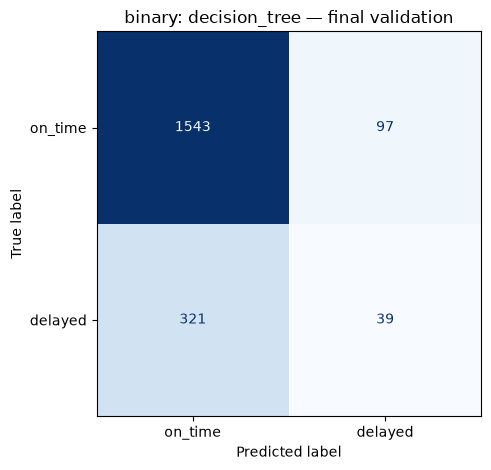

Fitting 5 folds for each of 3 candidates, totalling 15 fits
Validation accuracy:          0.8180
Validation balanced accuracy: 0.5020
Validation macro F1:          0.4580
Final training runtime:       13.1228 seconds
Prediction runtime:           0.3034 seconds


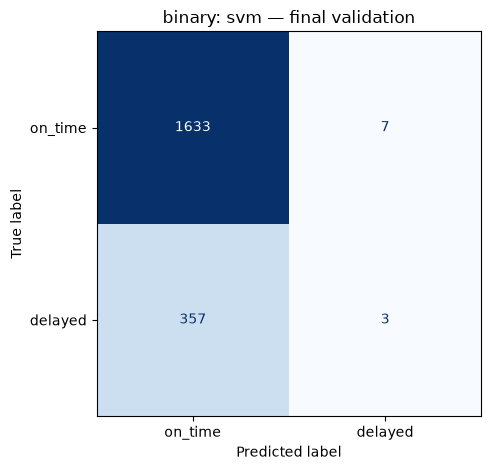

Fitting 5 folds for each of 10 candidates, totalling 50 fits


/Users/laurenlal/CSE5140/cse5104-project2/.venv-1/lib/python3.12/site-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


Validation accuracy:          0.7745
Validation balanced accuracy: 0.5102
Validation macro F1:          0.5024
Final training runtime:       0.0987 seconds
Prediction runtime:           0.4415 seconds


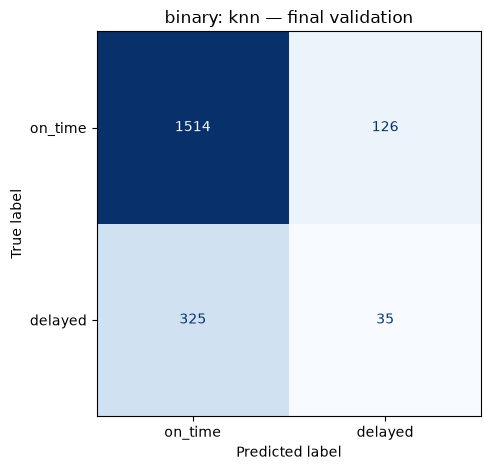

Fitting 5 folds for each of 10 candidates, totalling 50 fits
Validation accuracy:          0.6460
Validation balanced accuracy: 0.5663
Validation macro F1:          0.5359
Final training runtime:       0.2548 seconds
Prediction runtime:           0.0179 seconds


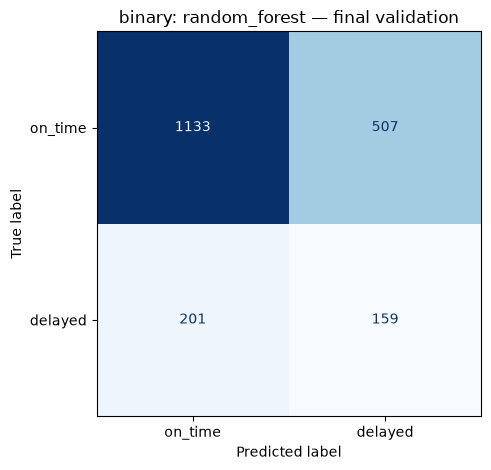

Fitting 5 folds for each of 5 candidates, totalling 25 fits
Validation accuracy:          0.2565
Validation balanced accuracy: 0.5141
Validation macro F1:          0.2525
Final training runtime:       0.2444 seconds
Prediction runtime:           0.0311 seconds


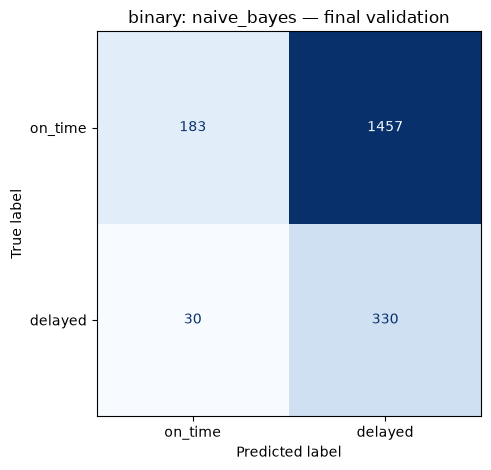

Fitting 5 folds for each of 5 candidates, totalling 25 fits
Validation accuracy:          0.8195
Validation balanced accuracy: 0.4997
Validation macro F1:          0.4504
Final training runtime:       0.6862 seconds
Prediction runtime:           0.0047 seconds


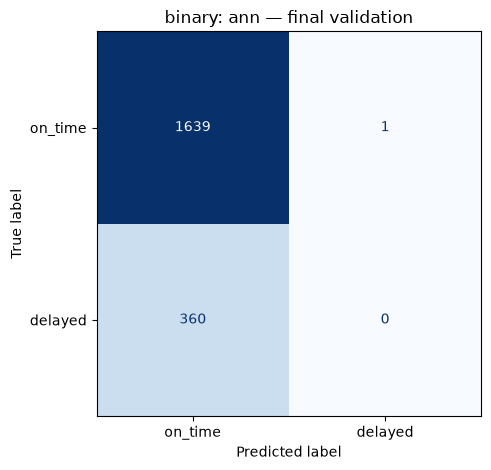

Fitting 5 folds for each of 5 candidates, totalling 25 fits
Validation accuracy:          0.7790
Validation balanced accuracy: 0.3477
Validation macro F1:          0.3437
Final training runtime:       0.2422 seconds
Prediction runtime:           0.0056 seconds


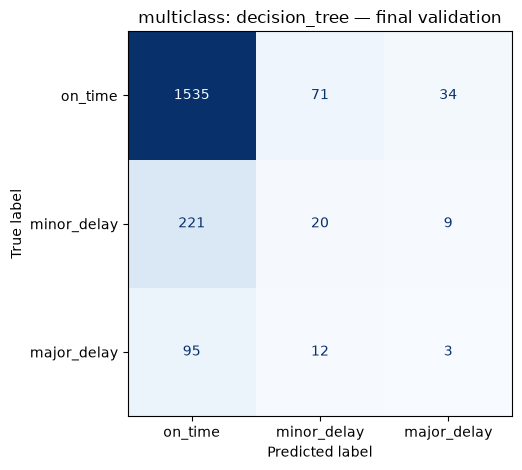

Fitting 5 folds for each of 3 candidates, totalling 15 fits
Validation accuracy:          0.8195
Validation balanced accuracy: 0.3365
Validation macro F1:          0.3081
Final training runtime:       14.4318 seconds
Prediction runtime:           0.3628 seconds


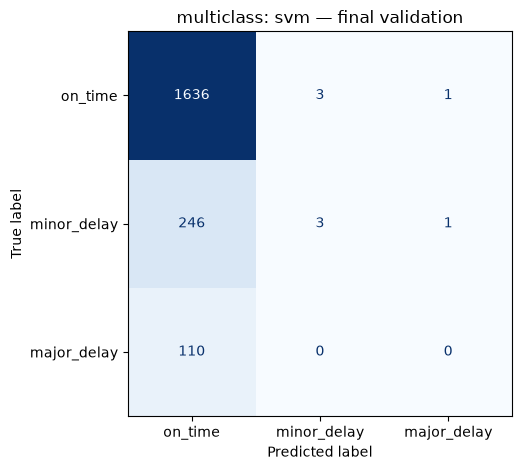

Fitting 5 folds for each of 10 candidates, totalling 50 fits


/Users/laurenlal/CSE5140/cse5104-project2/.venv-1/lib/python3.12/site-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


Validation accuracy:          0.7750
Validation balanced accuracy: 0.3450
Validation macro F1:          0.3404
Final training runtime:       0.1176 seconds
Prediction runtime:           0.4053 seconds


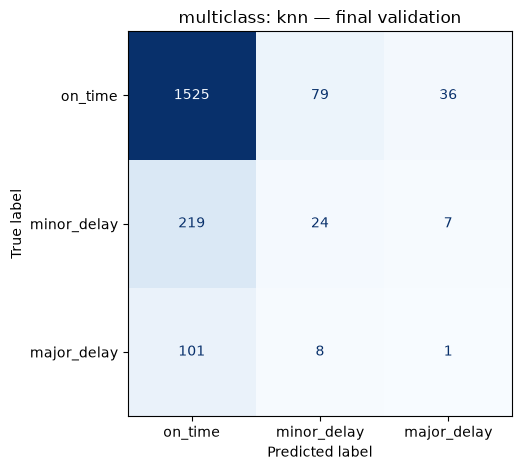

Fitting 5 folds for each of 10 candidates, totalling 50 fits
Validation accuracy:          0.6350
Validation balanced accuracy: 0.3819
Validation macro F1:          0.3651
Final training runtime:       0.2751 seconds
Prediction runtime:           0.0196 seconds


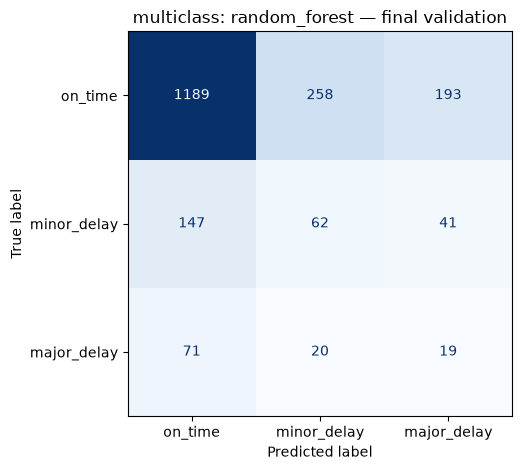

Fitting 5 folds for each of 5 candidates, totalling 25 fits
Validation accuracy:          0.1275
Validation balanced accuracy: 0.3600
Validation macro F1:          0.1266
Final training runtime:       0.2500 seconds
Prediction runtime:           0.0186 seconds


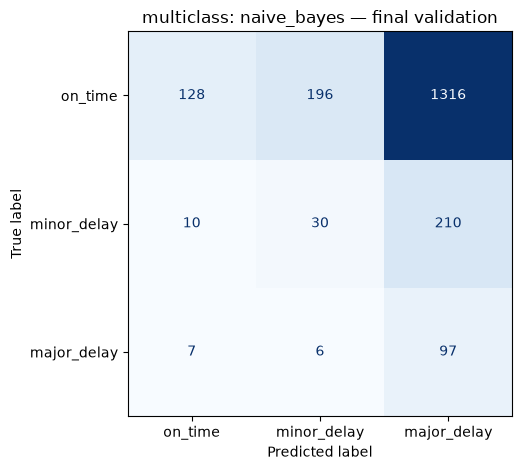

Fitting 5 folds for each of 5 candidates, totalling 25 fits
Validation accuracy:          0.8200
Validation balanced accuracy: 0.3333
Validation macro F1:          0.3004
Final training runtime:       0.4971 seconds
Prediction runtime:           0.0047 seconds


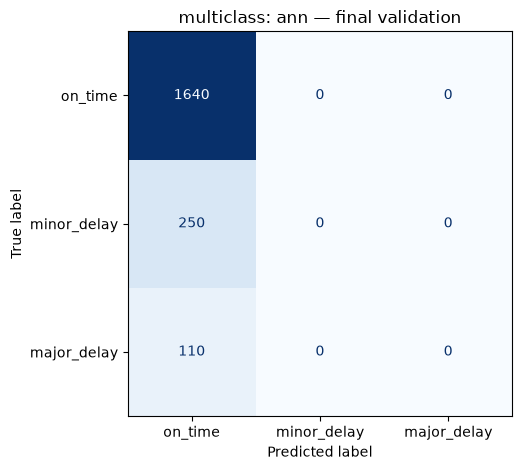

,classification,model,best_parameters,cv_macro_f1,validation_accuracy,validation_balanced_accuracy,validation_macro_f1,training_seconds,prediction_seconds
3,binary,random_forest,"{'model__class_weight': 'balanced', 'model__ma...",0.550550,0.6460,0.566260,0.535939,0.254815,0.017854
0,binary,decision_tree,{'model__max_depth': 20},0.519601,0.7910,0.524593,0.518983,0.231366,0.004364
2,binary,knn,"{'model__n_neighbors': 3, 'model__weights': 'd...",0.521893,0.7745,0.510196,0.502361,0.098683,0.441481
1,binary,svm,{'model__kernel': 'poly'},0.460428,0.8180,0.502033,0.457970,13.122753,0.303429
5,binary,ann,{'model__alpha': 0.0001},0.452322,0.8195,0.499695,0.450398,0.686203,0.004665
4,binary,naive_bayes,{'model__var_smoothing': 1e-06},0.240873,0.2565,0.514126,0.252462,0.244354,0.031063
9,multiclass,random_forest,"{'model__class_weight': 'balanced', 'model__ma...",0.377720,0.6350,0.381909,0.365097,0.275060,0.019639
6,multiclass,decision_tree,{'model__max_depth': 20},0.337846,0.7790,0.347749,0.343727,0.242215,0.005569
8,multiclass,knn,"{'model__n_neighbors': 3, 'model__weights': 'd...",0.346114,0.7750,0.344990,0.340377,0.117567,0.405339
7,multiclass,svm,{'model__kernel': 'poly'},0.305143,0.8195,0.336520,0.308106,14.431787,0.362782


In [17]:
results = []
best_models = {}
cv_tables = {}

for classification, split in splits.items():
    X_train, y_train, X_validation, y_validation = split

    folds = list(StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=SEED).split(X_train, y_train))

    for model in models:
        model_estimator, hyperparameters = model_specs[model]
        pipeline = make_pipeline(model_estimator)

        grid_search = GridSearchCV(
            estimator=pipeline,
            param_grid=hyperparameters,
            scoring="f1_macro",
            cv=folds,
            n_jobs=-1,
            verbose=1,
            refit=False,
        )

        grid_search.fit(X_train, y_train)

        cv_table = pd.DataFrame(grid_search.cv_results_)
        cv_tables[(classification, model)] = cv_table

        mean_test_scores = cv_table[["mean_test_score", "std_test_score"]].copy()

        best_index = mean_test_scores["mean_test_score"].idxmax()
        best_params = grid_search.cv_results_["params"][best_index]

        best_model = make_pipeline(model_estimator).set_params(**best_params)
        
        start_time = perf_counter()
        best_model.fit(X_train, y_train)
        fit_time = perf_counter() - start_time

        start_time = perf_counter()
        predictions = best_model.predict(X_validation)
        prediction_seconds = perf_counter() - start_time

        best_models[(classification, model)] = best_model
        accuracy = accuracy_score(y_validation, predictions)
        balanced_accuracy = balanced_accuracy_score(y_validation, predictions)
        macro_f1 = f1_score(y_validation, predictions, average="macro")

        labels = np.arange(len(class_names[classification]))

        print(f"Validation accuracy:          {accuracy:.4f}")
        print(f"Validation balanced accuracy: {balanced_accuracy:.4f}")
        print(f"Validation macro F1:          {macro_f1:.4f}")
        print(f"Final training runtime:       {fit_time:.4f} seconds")
        print(f"Prediction runtime:           {prediction_seconds:.4f} seconds")

        ConfusionMatrixDisplay.from_predictions(
            y_validation,
            predictions,
            labels=labels,
            display_labels=class_names[classification],
            cmap="Blues",
            colorbar=False,
        )

        plt.title(f"{classification}: {model} — final validation")
        plt.tight_layout()
        plt.show()

        results.append({
            "classification": classification,
            "model": model,
            "best_parameters": str(best_params),
            "cv_macro_f1": mean_test_scores.loc[best_index, "mean_test_score"],
            "validation_accuracy": accuracy,
            "validation_balanced_accuracy": balanced_accuracy,
            "validation_macro_f1": macro_f1,
            "training_seconds": fit_time,
            "prediction_seconds": prediction_seconds,
        })

results_df = pd.DataFrame(results)
display(results_df.sort_values(["classification", "validation_macro_f1"], ascending=[True, False]))
results_df.to_csv(OUTPUT_DIR / "model_fitting_results.csv", index=False)
for (classification, model), cv_table in cv_tables.items():
    cv_table.to_csv(OUTPUT_DIR / f"cv_results_{classification}_{model}.csv", index=False)  



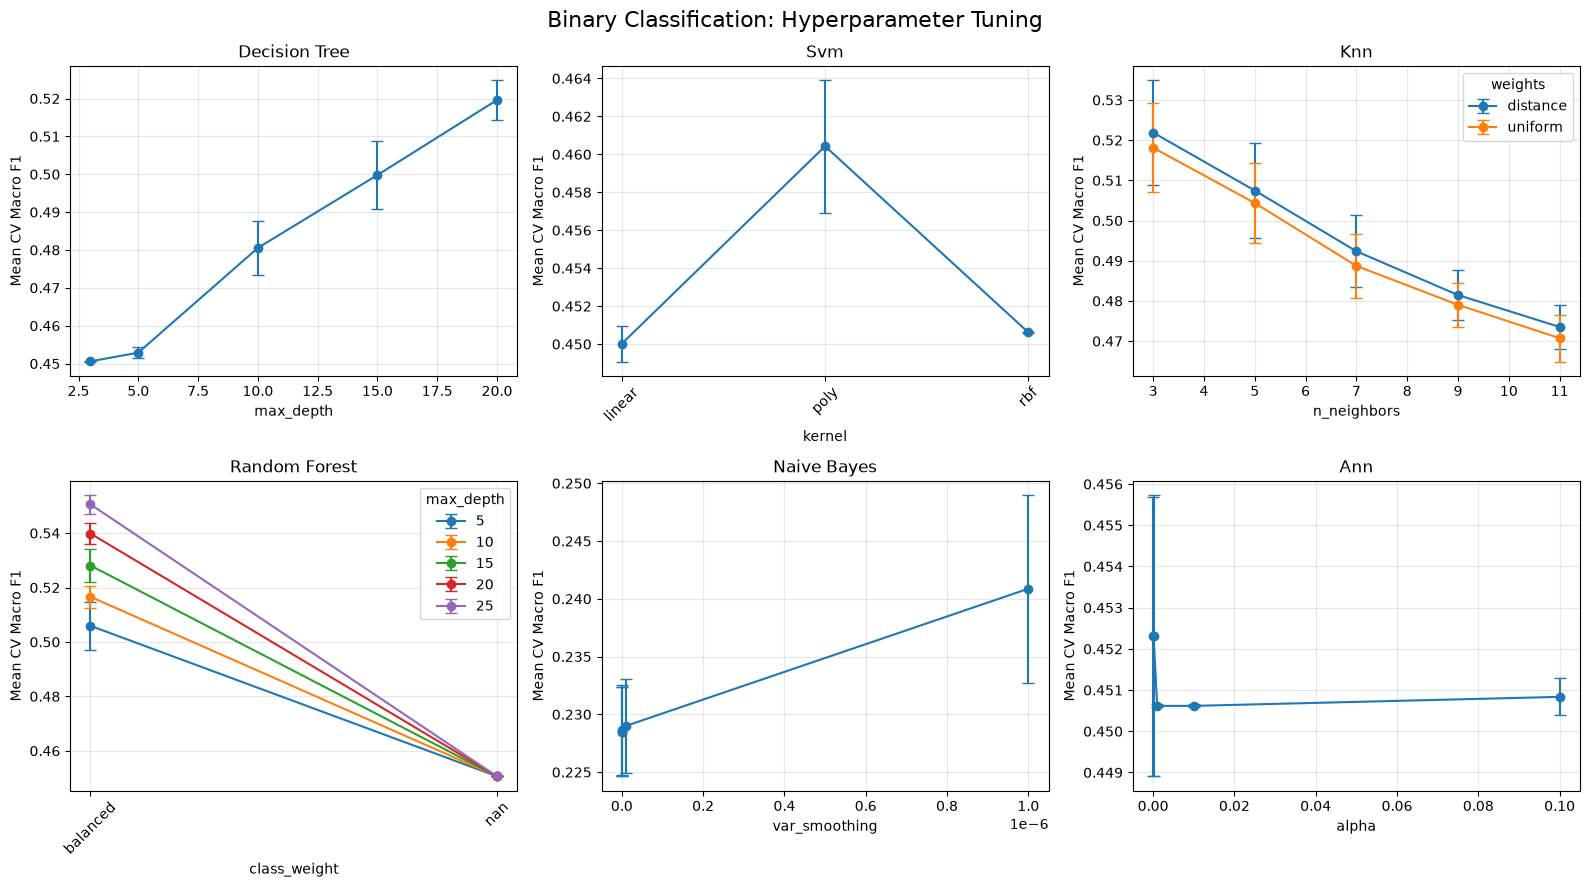

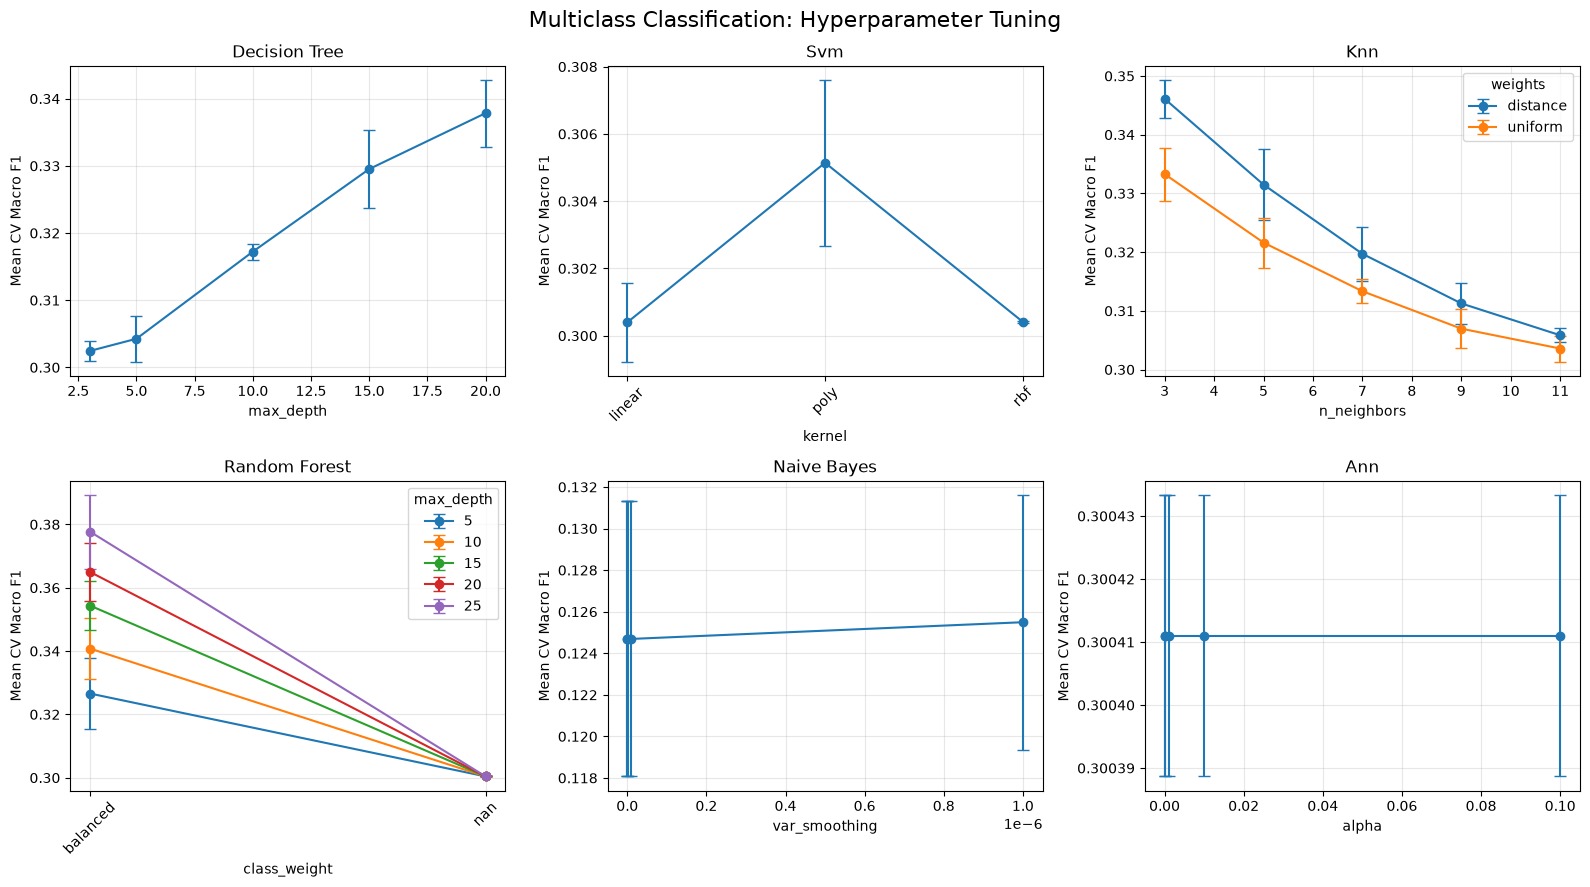

In [18]:

# Visualization: origial models

for classification in ["binary", "multiclass"]:

    fig, axes = plt.subplots(2, 3, figsize=(16, 9))
    axes = axes.flatten()

    for ax, model in zip(axes, model_specs.keys()):

        cv = cv_tables[(classification, model)].copy()

        params = [
            col for col in cv.columns
            if col.startswith("param_model__")
        ]

        x_param = params[0]
        group_param = params[1] if len(params) > 1 else None

        # Plot separate lines for second hyperparameter
        if group_param:
            groups = cv.groupby(group_param)
        else:
            groups = [("All", cv)]

        for group_name, group in groups:

            group = group.copy()

            try:
                group[x_param] = group[x_param].astype(float)
                group = group.sort_values(x_param)
                x = group[x_param].values
                numeric = True
            except (ValueError, TypeError):
                group = group.sort_values(x_param)
                x = np.arange(len(group))
                numeric = False

            ax.errorbar(
                x,
                group["mean_test_score"],
                yerr=group["std_test_score"],
                marker="o",
                capsize=4,
                label=str(group_name) if group_param else None
            )

            if not numeric:
                ax.set_xticks(x)
                ax.set_xticklabels(group[x_param], rotation=45)

        if group_param:
            ax.legend(title=group_param.replace("param_model__", ""))

        ax.set_title(model.replace("_", " ").title())
        ax.set_xlabel(x_param.replace("param_model__", ""))
        ax.set_ylabel("Mean CV Macro F1")
        ax.grid(alpha=0.3)

    fig.suptitle(
        f"{classification.capitalize()} Classification: "
        "Hyperparameter Tuning",
        fontsize=16
    )

    plt.tight_layout()
    plt.show()


## Part C: Dimension Reduction

Run the same piple except use a subset of features

In [19]:

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.feature_selection import mutual_info_classif

class OriginalFeatureSelector(BaseEstimator, TransformerMixin):
    def __init__(self, k=6, random_state=10):
        self.k = k
        self.random_state = random_state

    def fit(self, X, y):
        X = X.copy()
        scores_data = pd.DataFrame(index=X.index)

        for col in numeric_features:
            values = pd.to_numeric(X[col], errors="coerce")
            scores_data[col] = values.fillna(values.median())

        for col in categorical_features:
            values = X[col].astype("string").fillna("Missing")
            scores_data[col] = pd.Categorical(values).codes

        discrete_mask = [
            col in categorical_features
            for col in scores_data.columns
        ]

        scores = mutual_info_classif(
            scores_data,
            y,
            discrete_features=discrete_mask,
            random_state=self.random_state
        )

        self.feature_scores_ = pd.Series(
            scores,
            index=scores_data.columns
        ).sort_values(ascending=False)

        self.selected_features_ = (
            self.feature_scores_.head(self.k).index.tolist()
        )

        return self

    def transform(self, X):
        return X[self.selected_features_].copy()


Fitting 5 folds for each of 5 candidates, totalling 25 fits
Validation accuracy:          0.7985
Validation balanced accuracy: 0.5086
Validation macro F1:          0.4885
Final training runtime:       0.4175 seconds
Prediction runtime:           0.0051 seconds


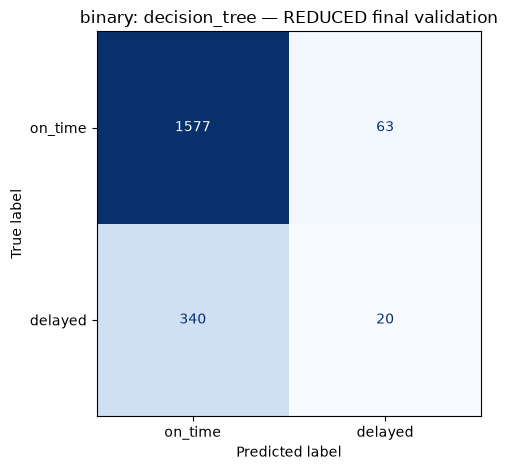

Fitting 5 folds for each of 3 candidates, totalling 15 fits
Validation accuracy:          0.8215
Validation balanced accuracy: 0.5107
Validation macro F1:          0.4748
Final training runtime:       7.7138 seconds
Prediction runtime:           0.2434 seconds


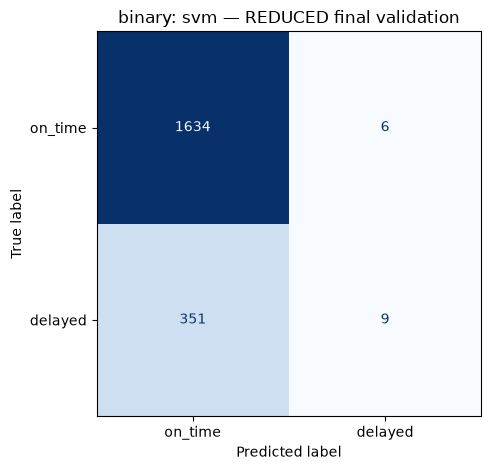

Fitting 5 folds for each of 10 candidates, totalling 50 fits


/Users/laurenlal/CSE5140/cse5104-project2/.venv-1/lib/python3.12/site-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


Validation accuracy:          0.7540
Validation balanced accuracy: 0.5313
Validation macro F1:          0.5329
Final training runtime:       0.4234 seconds
Prediction runtime:           0.2477 seconds


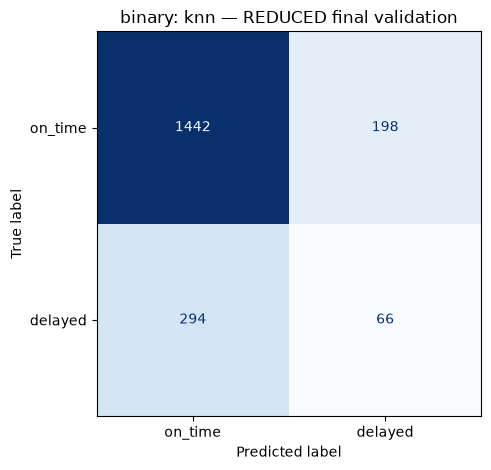

Fitting 5 folds for each of 10 candidates, totalling 50 fits
Validation accuracy:          0.6050
Validation balanced accuracy: 0.5716
Validation macro F1:          0.5214
Final training runtime:       0.5682 seconds
Prediction runtime:           0.0184 seconds


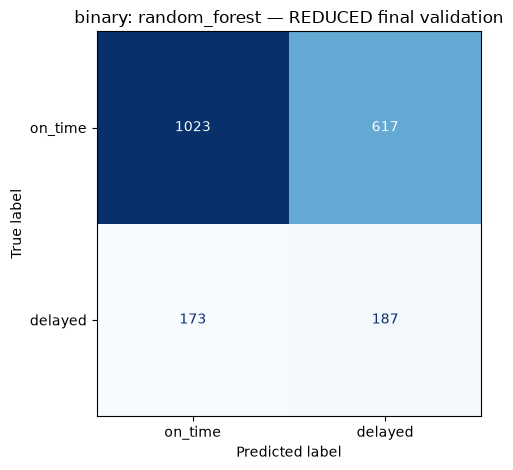

Fitting 5 folds for each of 5 candidates, totalling 25 fits
Validation accuracy:          0.2565
Validation balanced accuracy: 0.5141
Validation macro F1:          0.2525
Final training runtime:       0.4925 seconds
Prediction runtime:           0.0264 seconds


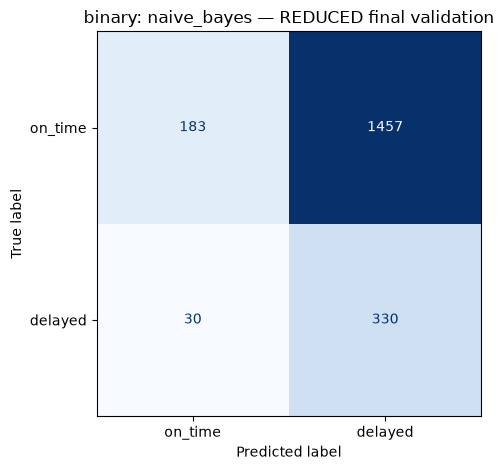

Fitting 5 folds for each of 5 candidates, totalling 25 fits
Validation accuracy:          0.8200
Validation balanced accuracy: 0.5000
Validation macro F1:          0.4505
Final training runtime:       0.7869 seconds
Prediction runtime:           0.0043 seconds


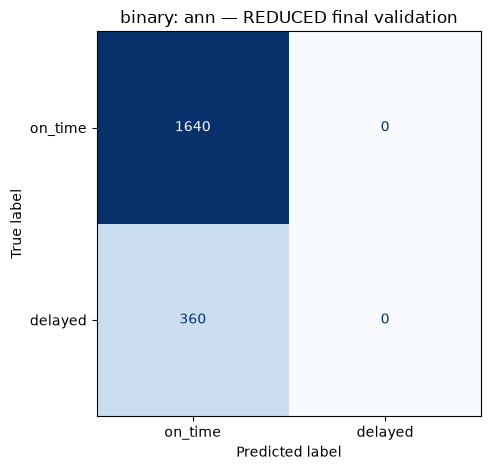

Fitting 5 folds for each of 5 candidates, totalling 25 fits
Validation accuracy:          0.8030
Validation balanced accuracy: 0.3456
Validation macro F1:          0.3335
Final training runtime:       0.4179 seconds
Prediction runtime:           0.0053 seconds


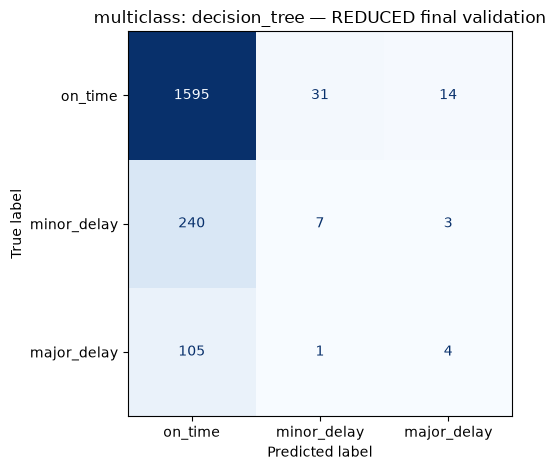

Fitting 5 folds for each of 3 candidates, totalling 15 fits
Validation accuracy:          0.8185
Validation balanced accuracy: 0.3361
Validation macro F1:          0.3078
Final training runtime:       8.9805 seconds
Prediction runtime:           0.2494 seconds


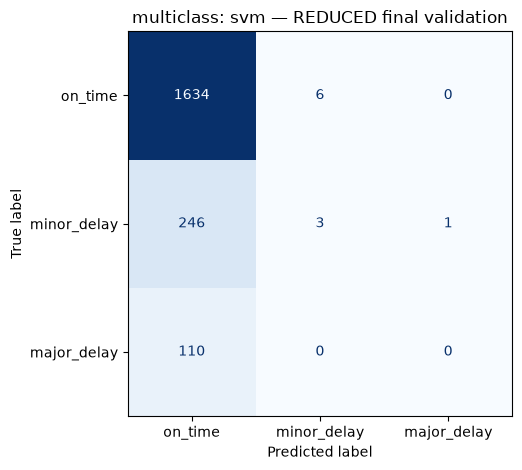

Fitting 5 folds for each of 10 candidates, totalling 50 fits
Validation accuracy:          0.7620
Validation balanced accuracy: 0.3623
Validation macro F1:          0.3645
Final training runtime:       0.4415 seconds
Prediction runtime:           0.2997 seconds


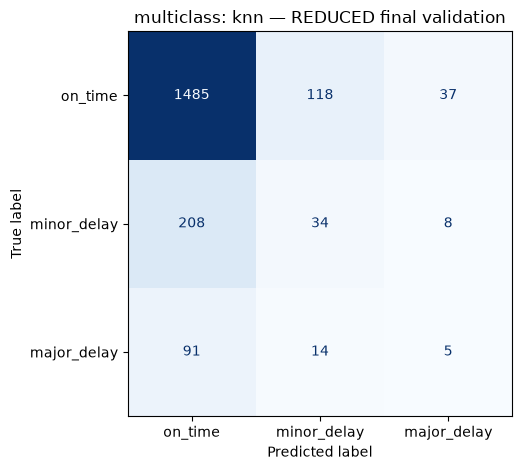

Fitting 5 folds for each of 10 candidates, totalling 50 fits
Validation accuracy:          0.5430
Validation balanced accuracy: 0.3852
Validation macro F1:          0.3406
Final training runtime:       0.5352 seconds
Prediction runtime:           0.0191 seconds


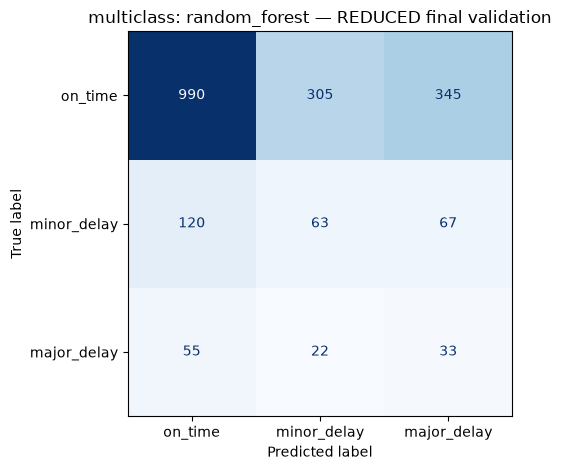

Fitting 5 folds for each of 5 candidates, totalling 25 fits
Validation accuracy:          0.1275
Validation balanced accuracy: 0.3600
Validation macro F1:          0.1266
Final training runtime:       0.4933 seconds
Prediction runtime:           0.0163 seconds


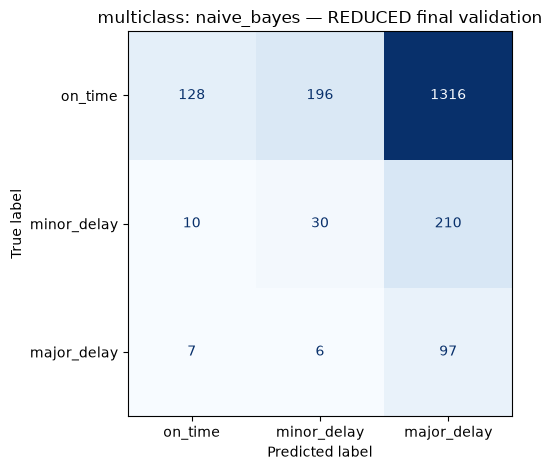

Fitting 5 folds for each of 5 candidates, totalling 25 fits
Validation accuracy:          0.8200
Validation balanced accuracy: 0.3333
Validation macro F1:          0.3004
Final training runtime:       0.7759 seconds
Prediction runtime:           0.0041 seconds


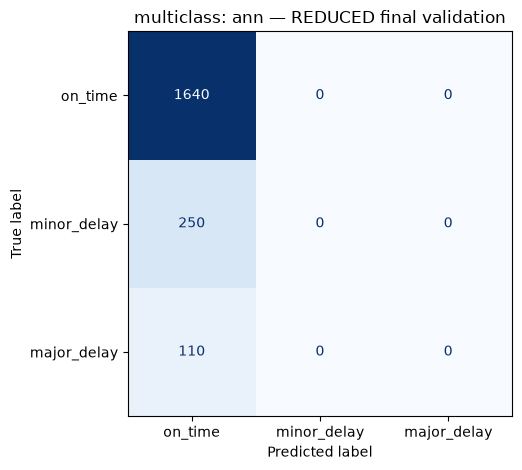

,classification,model,best_parameters,cv_macro_f1,validation_accuracy,validation_balanced_accuracy,validation_macro_f1,training_seconds,prediction_seconds,original_features,selected_features,selected_feature_names
2,binary,knn,"{'model__n_neighbors': 3, 'model__weights': 'd...",0.519610,0.7540,0.531301,0.532902,0.423448,0.247691,12,6,"['ORIGIN_AIRPORT', 'DESTINATION_AIRPORT', 'SCH..."
3,binary,random_forest,"{'model__class_weight': 'balanced', 'model__ma...",0.523822,0.6050,0.571612,0.521372,0.568182,0.018350,12,6,"['ORIGIN_AIRPORT', 'DESTINATION_AIRPORT', 'SCH..."
0,binary,decision_tree,{'model__max_depth': 20},0.491503,0.7985,0.508570,0.488498,0.417514,0.005063,12,6,"['ORIGIN_AIRPORT', 'DESTINATION_AIRPORT', 'SCH..."
1,binary,svm,{'model__kernel': 'poly'},0.458429,0.8215,0.510671,0.474759,7.713751,0.243417,12,6,"['ORIGIN_AIRPORT', 'DESTINATION_AIRPORT', 'SCH..."
5,binary,ann,{'model__alpha': 0.01},0.451951,0.8200,0.500000,0.450549,0.786913,0.004256,12,6,"['ORIGIN_AIRPORT', 'DESTINATION_AIRPORT', 'SCH..."
4,binary,naive_bayes,{'model__var_smoothing': 1e-06},0.240875,0.2565,0.514126,0.252462,0.492517,0.026421,12,6,"['ORIGIN_AIRPORT', 'DESTINATION_AIRPORT', 'SCH..."
8,multiclass,knn,"{'model__n_neighbors': 3, 'model__weights': 'd...",0.348137,0.7620,0.362314,0.364456,0.441484,0.299708,12,6,"['ORIGIN_AIRPORT', 'DESTINATION_AIRPORT', 'SCH..."
9,multiclass,random_forest,"{'model__class_weight': 'balanced', 'model__ma...",0.354191,0.5430,0.385220,0.340559,0.535178,0.019059,12,6,"['ORIGIN_AIRPORT', 'DESTINATION_AIRPORT', 'SCH..."
6,multiclass,decision_tree,{'model__max_depth': 20},0.324256,0.8030,0.345642,0.333524,0.417904,0.005286,12,6,"['ORIGIN_AIRPORT', 'DESTINATION_AIRPORT', 'SCH..."
7,multiclass,svm,{'model__kernel': 'poly'},0.308076,0.8185,0.336114,0.307814,8.980498,0.249399,12,6,"['ORIGIN_AIRPORT', 'DESTINATION_AIRPORT', 'SCH..."


In [20]:
red_results = []
red_best_models = {}
red_cv_tables = {}

for classification, split in splits.items():
    X_train, y_train, X_validation, y_validation = split

    folds = list(StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=SEED).split(X_train, y_train))

    for model in models:
        model_estimator, hyperparameters = model_specs[model]
        pipeline = make_pipeline(model_estimator, selected_features=True)

        grid_search = GridSearchCV(
            estimator=pipeline,
            param_grid=hyperparameters,
            scoring="f1_macro",
            cv=folds,
            n_jobs=-1,
            verbose=1,
            refit=False,
        )

        grid_search.fit(X_train, y_train)

        cv_table = pd.DataFrame(grid_search.cv_results_)
        red_cv_tables[(classification, model)] = cv_table

        mean_test_scores = cv_table[["mean_test_score", "std_test_score"]].copy()

        best_index = mean_test_scores["mean_test_score"].idxmax()
        best_params = grid_search.cv_results_["params"][best_index]

        best_model = make_pipeline(model_estimator, selected_features=True).set_params(**best_params)
        
        start_time = perf_counter()
        best_model.fit(X_train, y_train)
        fit_time = perf_counter() - start_time

        start_time = perf_counter()
        predictions = best_model.predict(X_validation)
        prediction_seconds = perf_counter() - start_time

        red_best_models[(classification, model)] = best_model
        accuracy = accuracy_score(y_validation, predictions)
        balanced_accuracy = balanced_accuracy_score(y_validation, predictions)
        macro_f1 = f1_score(y_validation, predictions, average="macro")

        labels = np.arange(len(class_names[classification]))

        print(f"Validation accuracy:          {accuracy:.4f}")
        print(f"Validation balanced accuracy: {balanced_accuracy:.4f}")
        print(f"Validation macro F1:          {macro_f1:.4f}")
        print(f"Final training runtime:       {fit_time:.4f} seconds")
        print(f"Prediction runtime:           {prediction_seconds:.4f} seconds")

        ConfusionMatrixDisplay.from_predictions(
            y_validation,
            predictions,
            labels=labels,
            display_labels=class_names[classification],
            cmap="Blues",
            colorbar=False,
        )

        plt.title(f"{classification}: {model} — REDUCED final validation")
        plt.tight_layout()
        plt.show()


        red_results.append({
            "classification": classification,
            "model": model,
            "best_parameters": str(best_params),
            "cv_macro_f1": mean_test_scores.loc[best_index, "mean_test_score"],
            "validation_accuracy": accuracy,
            "validation_balanced_accuracy": balanced_accuracy,
            "validation_macro_f1": macro_f1,
            "training_seconds": fit_time,
            "prediction_seconds": prediction_seconds,

           "original_features": len(numeric_features + categorical_features),
           "selected_features": len(best_model.named_steps["feature_selection"].selected_features_),
           "selected_feature_names": str(best_model.named_steps["feature_selection"].selected_features_)
        })

        

red_results_df = pd.DataFrame(red_results)
display(red_results_df.sort_values(["classification", "validation_macro_f1"], ascending=[True, False]))
red_results_df.to_csv(OUTPUT_DIR / "model_fitting_results_reduced.csv", index=False)
for (classification, model), cv_table in red_cv_tables.items():
    cv_table.to_csv(OUTPUT_DIR / f"cv_results_reduced_{classification}_{model}.csv", index=False)

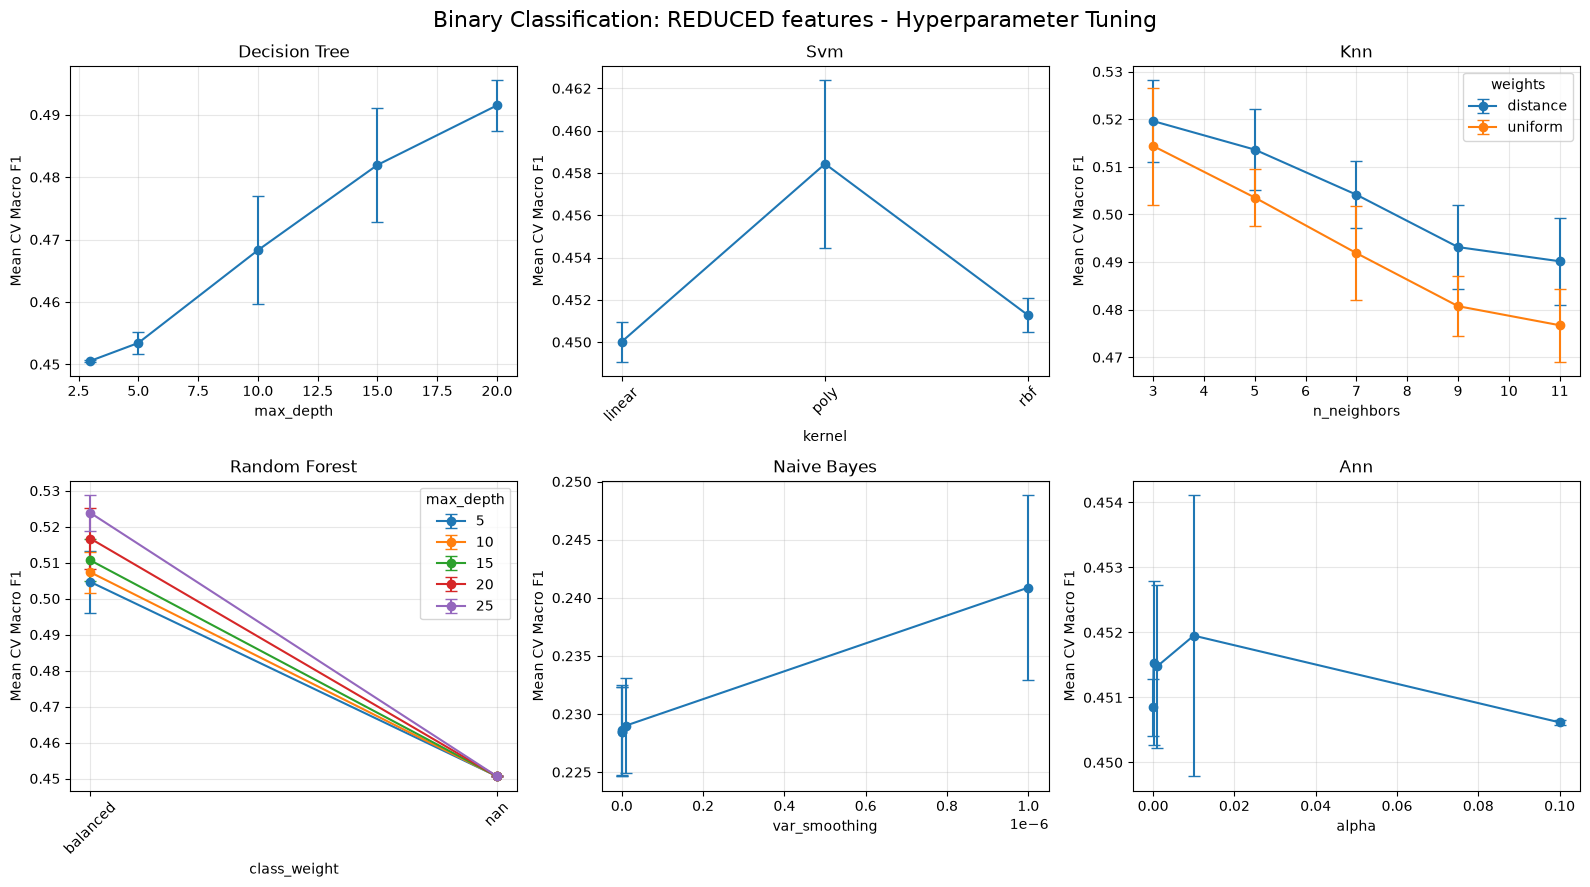

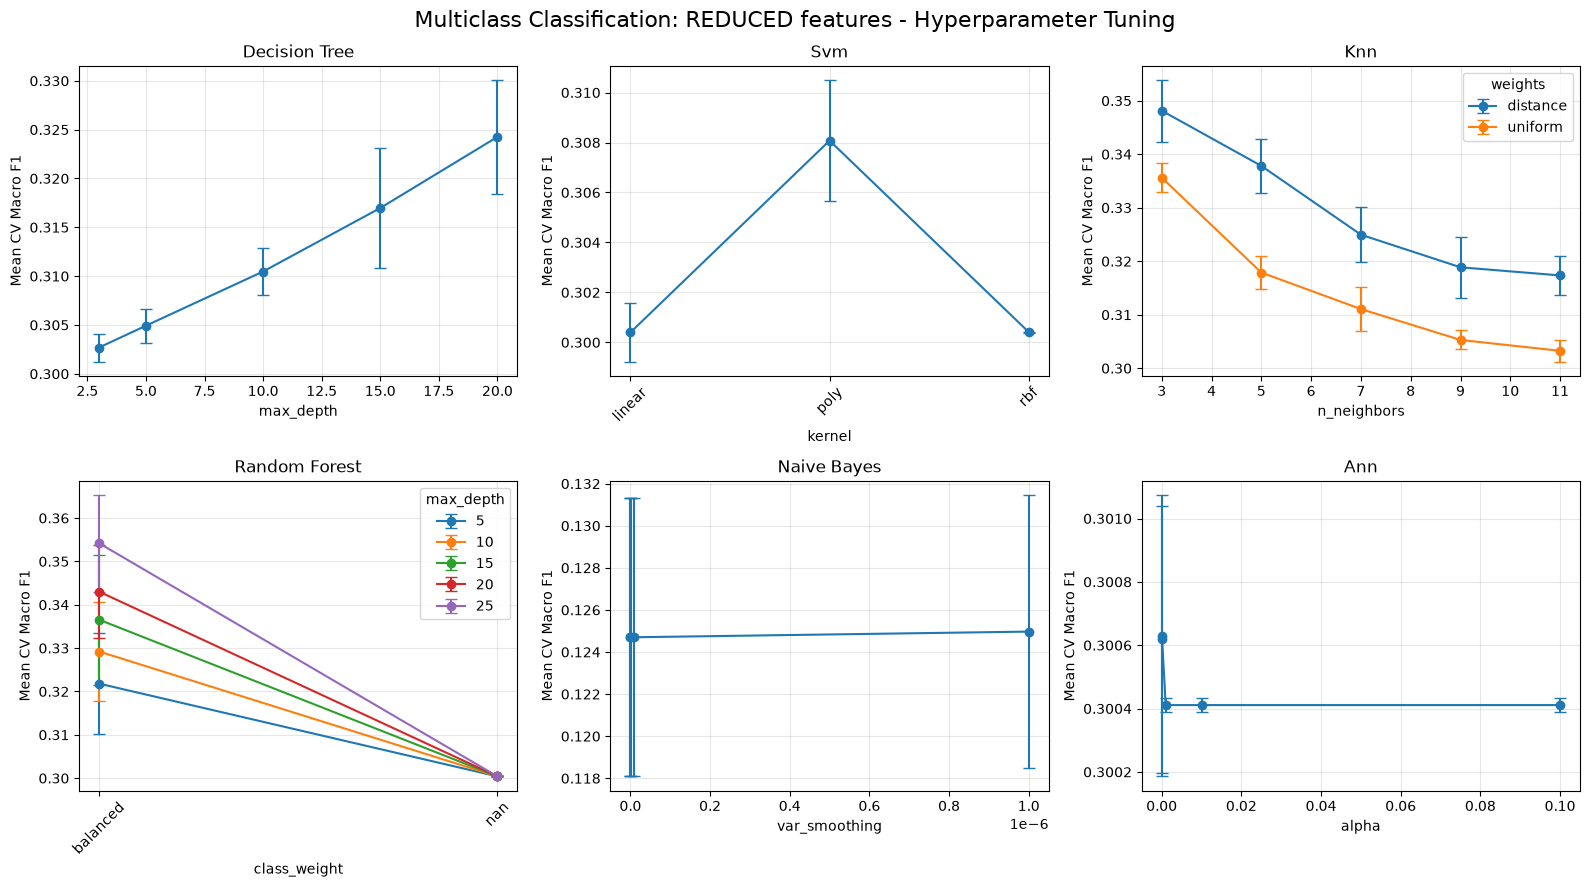

In [30]:

# Visualization: reduced models

for classification in ["binary", "multiclass"]:

    fig, axes = plt.subplots(2, 3, figsize=(16, 9))
    axes = axes.flatten()

    for ax, model in zip(axes, model_specs.keys()):

        cv = red_cv_tables[(classification, model)].copy()

        params = [
            col for col in cv.columns
            if col.startswith("param_model__")
        ]



        x_param = params[0]
        group_param = params[1] if len(params) > 1 else None

        # Plot separate lines for second hyperparameter
        if group_param:
            groups = cv.groupby(group_param)
        else:
            groups = [("All", cv)]

        for group_name, group in groups:

            group = group.copy()

            try:
                group[x_param] = group[x_param].astype(float)
                group = group.sort_values(x_param)
                x = group[x_param].values
                numeric = True
            except (ValueError, TypeError):
                group = group.sort_values(x_param)
                x = np.arange(len(group))
                numeric = False

            ax.errorbar(
                x,
                group["mean_test_score"],
                yerr=group["std_test_score"],
                marker="o",
                capsize=4,
                label=str(group_name) if group_param else None
            )

            if not numeric:
                ax.set_xticks(x)
                ax.set_xticklabels(group[x_param], rotation=45)

        if group_param:
            ax.legend(title=group_param.replace("param_model__", ""))

        ax.set_title(model.replace("_", " ").title())
        ax.set_xlabel(x_param.replace("param_model__", ""))
        ax.set_ylabel("Mean CV Macro F1")
        ax.grid(alpha=0.3)

    fig.suptitle(
        f"{classification.capitalize()} Classification: "
        "REDUCED features - Hyperparameter Tuning",
        fontsize=16
    )

    plt.tight_layout()
    plt.show()


Comparison of original to reduced features

In [22]:
comparison = results_df.merge(
    red_results_df,
    on=["classification", "model"],
    suffixes=("_original", "_reduced")
)

comparison["f1_change"] = (
    comparison["validation_macro_f1_reduced"]
    - comparison["validation_macro_f1_original"]
)

display(comparison[[
    "classification",
    "model",
    "validation_macro_f1_original",
    "validation_macro_f1_reduced",
    "f1_change"
]])

,classification,model,validation_macro_f1_original,validation_macro_f1_reduced,f1_change
0,binary,decision_tree,0.518983,0.488498,-0.030485
1,binary,svm,0.457970,0.474759,0.016788
2,binary,knn,0.502361,0.532902,0.030541
3,binary,random_forest,0.535939,0.521372,-0.014567
4,binary,naive_bayes,0.252462,0.252462,0.000000
5,binary,ann,0.450398,0.450549,0.000151
6,multiclass,decision_tree,0.343727,0.333524,-0.010202
7,multiclass,svm,0.308106,0.307814,-0.000292
8,multiclass,knn,0.340377,0.364456,0.024079
9,multiclass,random_forest,0.365097,0.340559,-0.024539


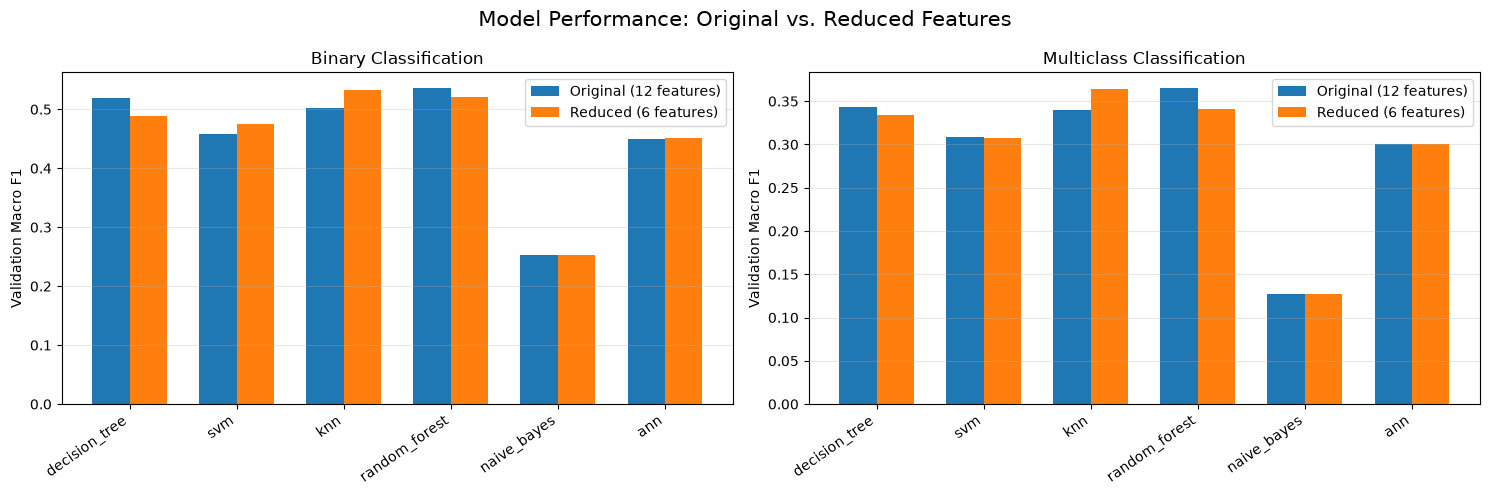

In [23]:
#Visualize comparisons

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

for ax, classification in zip(
    axes, ["binary", "multiclass"]
):
    subset = comparison[
        comparison["classification"] == classification
    ].copy()

    x = np.arange(len(subset))
    width = 0.35

    ax.bar(
        x - width / 2,
        subset["validation_macro_f1_original"],
        width,
        label="Original (12 features)"
    )

    ax.bar(
        x + width / 2,
        subset["validation_macro_f1_reduced"],
        width,
        label="Reduced (6 features)"
    )

    ax.set_xticks(x)
    ax.set_xticklabels(
        subset["model"],
        rotation=35,
        ha="right"
    )

    ax.set_title(f"{classification.capitalize()} Classification")
    ax.set_ylabel("Validation Macro F1")
    ax.legend()
    ax.grid(axis="y", alpha=0.3)

plt.suptitle(
    "Model Performance: Original vs. Reduced Features",
    fontsize=15
)
plt.tight_layout()
plt.show()


In [24]:
#runtimes

runtime_cols = [
    "classification",
    "model",
    "training_seconds_original",
    "training_seconds_reduced",
    "prediction_seconds_original",
    "prediction_seconds_reduced"
]

display(comparison[runtime_cols].round(4))


,classification,model,training_seconds_original,training_seconds_reduced,prediction_seconds_original,prediction_seconds_reduced
0,binary,decision_tree,0.2314,0.4175,0.0044,0.0051
1,binary,svm,13.1228,7.7138,0.3034,0.2434
2,binary,knn,0.0987,0.4234,0.4415,0.2477
3,binary,random_forest,0.2548,0.5682,0.0179,0.0184
4,binary,naive_bayes,0.2444,0.4925,0.0311,0.0264
5,binary,ann,0.6862,0.7869,0.0047,0.0043
6,multiclass,decision_tree,0.2422,0.4179,0.0056,0.0053
7,multiclass,svm,14.4318,8.9805,0.3628,0.2494
8,multiclass,knn,0.1176,0.4415,0.4053,0.2997
9,multiclass,random_forest,0.2751,0.5352,0.0196,0.0191


In [ ]:
#Part C: 3.1 Export and 4.1 export 

from pathlib import Path

output_dir = Path("project2_output")
output_dir.mkdir(exist_ok=True)

for classification in ["binary", "multiclass"]:
    selector = red_best_models[
        (classification, "random_forest")
    ].named_steps["feature_selection"]

    X_train, y_train, X_val, y_val = splits[classification]
    target = f"{classification}_response"


    for name, X, y in [
        ("train", X_train, y_train),
        ("validation", X_val, y_val)
    ]:
        reduced = selector.transform(X).copy()
        reduced[target] = y.to_numpy()

        reduced.to_csv(
            output_dir / f"flights_reduced_{classification}_{name}.csv",
            index=False
        )

    print(classification, selector.selected_features_)

binary ['ORIGIN_AIRPORT', 'DESTINATION_AIRPORT', 'SCHEDULED_DEPARTURE_HOUR', 'SCHEDULED_ARRIVAL_HOUR', 'DISTANCE', 'AIRLINE']
multiclass ['ORIGIN_AIRPORT', 'DESTINATION_AIRPORT', 'SCHEDULED_DEPARTURE_HOUR', 'SCHEDULED_ARRIVAL_HOUR', 'MONTH', 'DISTANCE']


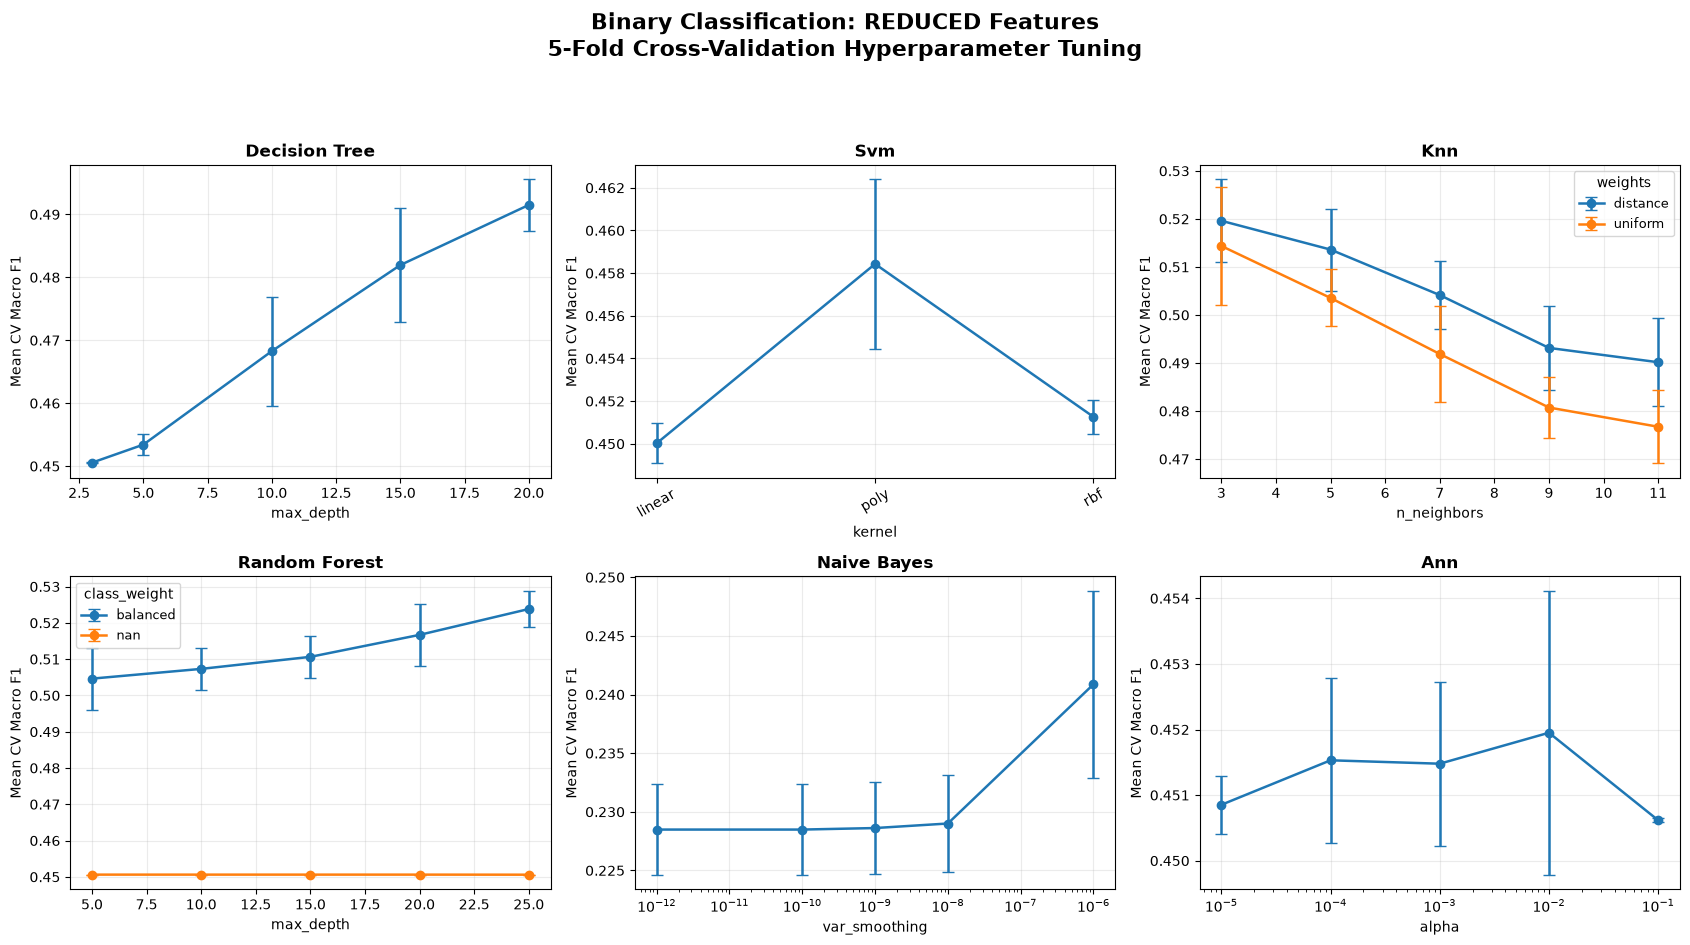

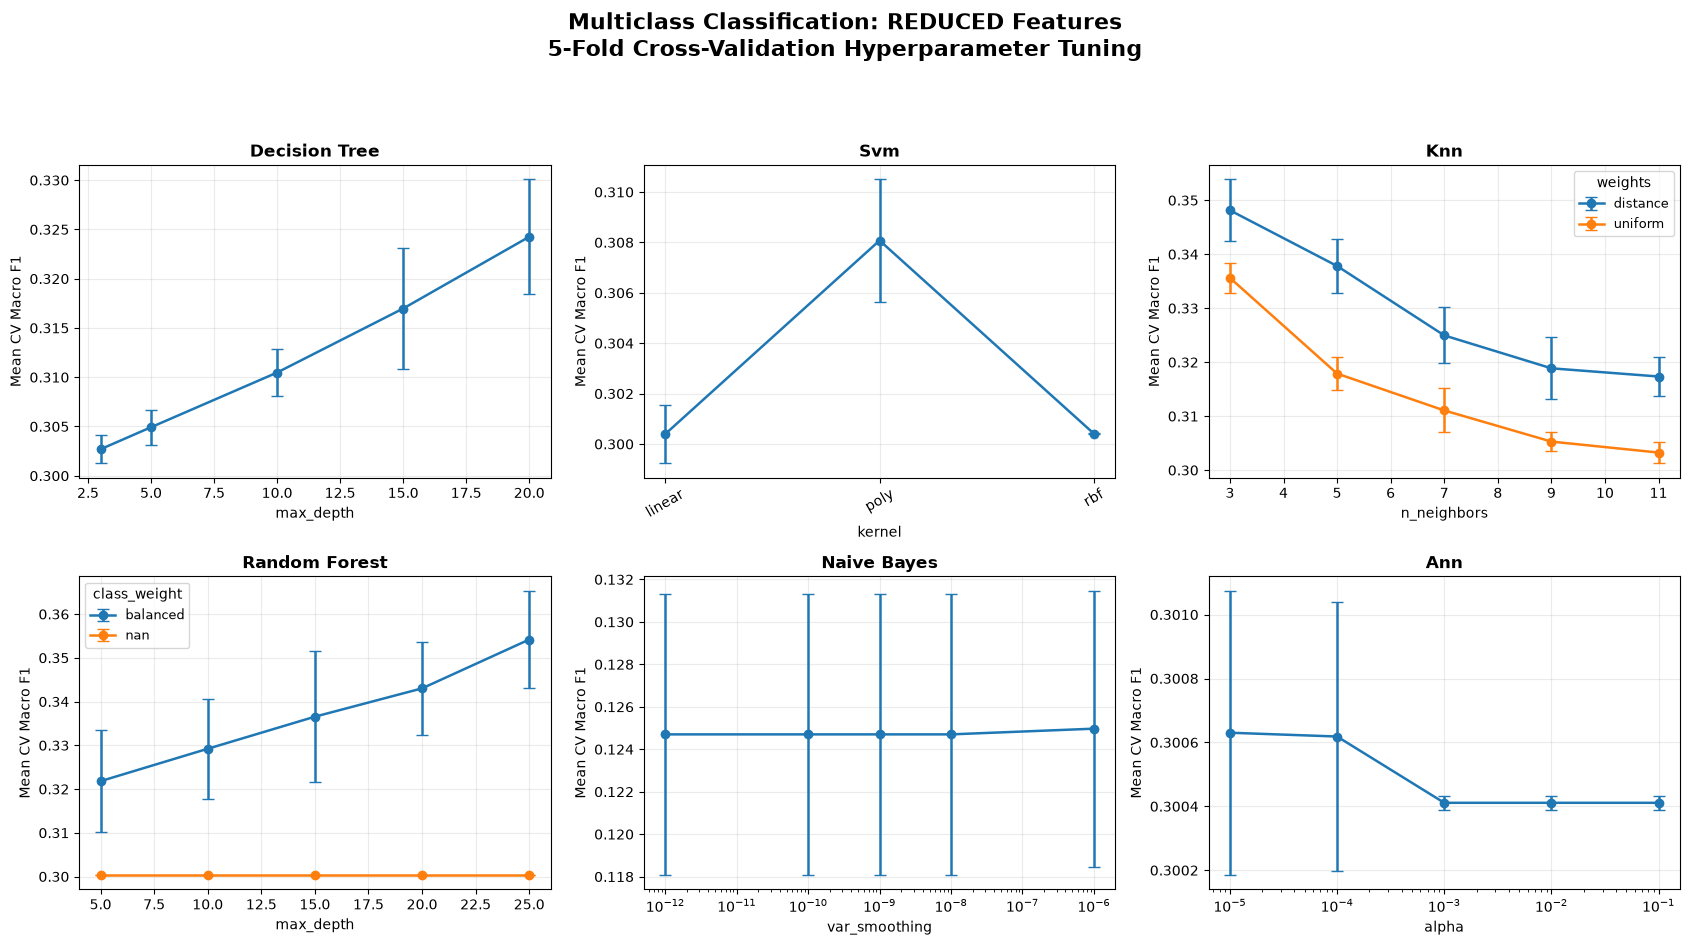

In [ ]:
#Part 3: 3.2 Visualizations and 4.2 viz 

for feature_set, tables in [
    ("REDUCED", red_cv_tables)
]:
    for classification in ["binary", "multiclass"]:

        fig, axes = plt.subplots(2, 3, figsize=(17, 10))
        axes = axes.flatten()

        for ax, model in zip(axes, model_specs.keys()):

            cv = tables[(classification, model)].copy()

            params = [
                col for col in cv.columns
                if col.startswith("param_model__")
            ]

            # Append edge cases for graphs 
            if model == "random_forest":
                x_param = "param_model__max_depth"
                group_param = "param_model__class_weight"

            elif model == "knn":
                x_param = "param_model__n_neighbors"
                group_param = "param_model__weights"

            else:
                x_param = params[0]
                group_param = None

            # Create groups for multi-parameter models
            if group_param:
                groups = cv.groupby(group_param, dropna=False)
            else:
                groups = [("All", cv)]

            for group_name, group in groups:

                group = group.copy()

                numeric = pd.to_numeric(group[x_param], errors="coerce")

                if numeric.notna().all():
                    group["_x"] = numeric
                    group = group.sort_values("_x")
                    x = group["_x"].to_numpy()
                    is_numeric = True

                else:
                    group = group.sort_values(
                        x_param, key=lambda s: s.astype(str)
                    )
                    x = np.arange(len(group))
                    is_numeric = False

                ax.errorbar(
                    x,
                    group["mean_test_score"],
                    yerr=group["std_test_score"],
                    marker="o",
                    capsize=4,
                    linewidth=1.8,
                    label=str(group_name) if group_param else None
                )

                if not is_numeric:
                    ax.set_xticks(x)
                    
                    ax.set_xticklabels(
                        group[x_param].astype(str),
                        rotation=30
                    )

            # Log scale for NB and ANN bc bad 
            if model in ["naive_bayes", "ann"]:
                ax.set_xscale("log")

            if group_param:
                ax.legend(
                    title=group_param.replace("param_model__", ""),
                    fontsize=9
                )

            ax.set_title(
                model.replace("_", " ").title(),
                fontsize=12,
                fontweight="bold"
            )

            ax.set_xlabel(
                x_param.replace("param_model__", "")
            )
            ax.set_ylabel("Mean CV Macro F1")
            ax.grid(alpha=0.25)

        fig.suptitle(
            f"{classification.capitalize()} Classification: "
            f"{feature_set} Features\n"
            "5-Fold Cross-Validation Hyperparameter Tuning",
            fontsize=16,
            fontweight="bold"
        )


        plt.tight_layout(rect=[0, 0.04, 1, 0.93])

        # Save each figure separately
        filename = (
            f"project2_output/"
            f"{feature_set.lower()}_{classification}_cv.png"
        )

        plt.savefig(
            filename,
            dpi=300,
            bbox_inches="tight"
        )

        plt.show()

In [40]:
#Part C 3.3

red_results_df.loc[
        red_results_df["classification"] == "binary",
        ["model", "best_parameters", "cv_macro_f1"]
    ]



,model,best_parameters,cv_macro_f1
0,decision_tree,{'model__max_depth': 20},0.491503
1,svm,{'model__kernel': 'poly'},0.458429
2,knn,"{'model__n_neighbors': 3, 'model__weights': 'd...",0.519610
3,random_forest,"{'model__class_weight': 'balanced', 'model__ma...",0.523822
4,naive_bayes,{'model__var_smoothing': 1e-06},0.240875
5,ann,{'model__alpha': 0.01},0.451951


In [43]:
#Part C 3.4

columns = [
    "model",
    "cv_macro_f1",
    "training_seconds"
]

red_results_df.loc[red_results_df["classification"] == "binary", columns].round(4)



,model,cv_macro_f1,training_seconds
0,decision_tree,0.4915,0.4175
1,svm,0.4584,7.7138
2,knn,0.5196,0.4234
3,random_forest,0.5238,0.5682
4,naive_bayes,0.2409,0.4925
5,ann,0.4520,0.7869


In [44]:

columns = [
    "model",
    "validation_accuracy",
    "validation_balanced_accuracy",
    "prediction_seconds"
]

red_results_df.loc[red_results_df["classification"] == "binary", columns].round(4)



,model,validation_accuracy,validation_balanced_accuracy,prediction_seconds
0,decision_tree,0.7985,0.5086,0.0051
1,svm,0.8215,0.5107,0.2434
2,knn,0.7540,0.5313,0.2477
3,random_forest,0.6050,0.5716,0.0184
4,naive_bayes,0.2565,0.5141,0.0264
5,ann,0.8200,0.5000,0.0043


In [46]:
#4.3
red_results_df.loc[
        red_results_df["classification"] == "multiclass",

        ["model", "best_parameters", "cv_macro_f1"]
    ]

,model,best_parameters,cv_macro_f1
6,decision_tree,{'model__max_depth': 20},0.324256
7,svm,{'model__kernel': 'poly'},0.308076
8,knn,"{'model__n_neighbors': 3, 'model__weights': 'd...",0.348137
9,random_forest,"{'model__class_weight': 'balanced', 'model__ma...",0.354191
10,naive_bayes,{'model__var_smoothing': 1e-06},0.124970
11,ann,{'model__alpha': 1e-05},0.300630


In [47]:
#4.4 
#Part C 3.4

columns = [
    "model",
    "cv_macro_f1",
    "training_seconds"
]

red_results_df.loc[red_results_df["classification"] == "multiclass", columns].round(4)



,model,cv_macro_f1,training_seconds
6,decision_tree,0.3243,0.4179
7,svm,0.3081,8.9805
8,knn,0.3481,0.4415
9,random_forest,0.3542,0.5352
10,naive_bayes,0.1250,0.4933
11,ann,0.3006,0.7759


In [48]:
#4.4 

columns = [
    "model",
    "validation_accuracy",
    "validation_balanced_accuracy",
    "prediction_seconds"
]

red_results_df.loc[red_results_df["classification"] == "multiclass", columns].round(4)



,model,validation_accuracy,validation_balanced_accuracy,prediction_seconds
6,decision_tree,0.8030,0.3456,0.0053
7,svm,0.8185,0.3361,0.2494
8,knn,0.7620,0.3623,0.2997
9,random_forest,0.5430,0.3852,0.0191
10,naive_bayes,0.1275,0.3600,0.0163
11,ann,0.8200,0.3333,0.0041
